In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import pandas as pd

In [2]:
# =====================================================
# 1. Parameters
# =====================================================

N = 1_000_000

params = {
    "beta": 0.6,
    "phi": 0.005,
    "eps": 0.8,
    "sigma": 0.25,
    "gamma": 0.2,
    "omegaV": 1 / 365,
    "omegaN": 1 / (365 * 2),
    "lambda": 0.5,
    "mu": 0.05,
    "k": 10,
    "Tc": 0.5,
}

# Costs
CI = 10.0     # infection cost
CV = 0.02     # vaccination cost


# Initial conditions
S0 = 999900
V0 = 0
E0 = 0
I0 = 100
RN0 = 0
RV0 = 0
T0 = 0.5

y0 = [S0, V0, E0, I0, RN0, RV0, T0]

t_start = 0
t_end = 3000

# High resolution (for main plots)
t_eval = np.linspace(t_start, t_end, 2000)

# Lower resolution (for heatmap → faster)
t_eval_heatmap = np.linspace(t_start, t_end,800)

In [3]:
# 2. Functions
# =====================================================

def sigmoid_trust(T, k, Tc):
    return 1 / (1 + np.exp(-k * (T - Tc)))


def model_BDO(t, y, p):
    S, V, E, I, RN, RV, T = y

    beta = p["beta"]
    phi = p["phi"]
    eps = p["eps"]
    sigma = p["sigma"]
    gamma = p["gamma"]
    omegaV = p["omegaV"]
    omegaN = p["omegaN"]
    lam = p["lambda"]
    mu = p["mu"]
    k = p["k"]
    Tc = p["Tc"]

    x = sigmoid_trust(T, k, Tc)

    dS = -beta * S * I / N - phi * x * S + omegaN * RN + omegaV * RV
    dV = phi * x * S - (1 - eps) * beta * V * I / N
    dE = beta * S * I / N + (1 - eps) * beta * V * I / N - sigma * E
    dI = sigma * E - gamma * I
    dRN = (1 - x) * gamma * I - omegaN * RN
    dRV = x * gamma * I - omegaV * RV
    dT = lam * (I / N) - mu * T

    return [dS, dV, dE, dI, dRN, dRV, dT]


def model_constant_x(t, y, p, x_const):
    S, V, E, I, RN, RV, T = y
    beta = p["beta"]
    phi = p["phi"]
    eps = p["eps"]
    sigma = p["sigma"]
    gamma = p["gamma"]
    omegaV = p["omegaV"]
    omegaN = p["omegaN"]
    lam = p["lambda"]
    mu = p["mu"]

    x = x_const

    dS = -beta * S * I / N - phi * x * S + omegaN * RN + omegaV * RV
    dV = phi * x * S - (1 - eps) * beta * V * I / N
    dE = beta * S * I / N + (1 - eps) * beta * V * I / N - sigma * E
    dI = sigma * E - gamma * I
    dRN = (1 - x) * gamma * I - omegaN * RN
    dRV = x * gamma * I - omegaV * RV
    dT = lam * (I / N) - mu * T
    return [dS, dV, dE, dI, dRN, dRV, dT]

In [4]:

import numpy as np
from scipy.integrate import solve_ivp

# Fixed numerical settings for both comparisons
T_END = 3000
ATOL_CHECK = 1e-11
TOLS = [1e-8, 1e-9]

t_lm = np.linspace(0, T_END, 2000)
t_econ = np.linspace(0, T_END, 4001)

lam_values = np.linspace(0.1, 1.0, 20)
mu_values = np.linspace(0.01, 0.2, 20)

ci_values = np.linspace(1, 20, 20)
cv_values = np.linspace(0.01, 20, 25)
x_candidates = np.linspace(0, 1, 101)

def integrate_checked(fun, args, grid, rtol):
    sol = solve_ivp(
        fun, (0, T_END), y0,
        args=args,
        t_eval=grid,
        method="DOP853",
        rtol=rtol,
        atol=ATOL_CHECK
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

def payoff_components(sol, x):
    S = sol.y[0]
    I = sol.y[3]
    return (
        np.trapezoid(I / N, sol.t),
        np.trapezoid(params["phi"] * x * S / N, sol.t)
    )

def compute_results(rtol):
    # Lambda-mu sensitivity
    bdo = np.zeros((20, 20))

    for i, mu in enumerate(mu_values):
        for j, lam in enumerate(lam_values):
            p = params.copy()
            p["lambda"] = float(lam)
            p["mu"] = float(mu)

            sol = integrate_checked(
                model_BDO, (p,), t_lm, rtol
            )
            x = sigmoid_trust(
                sol.y[6], p["k"], p["Tc"]
            )
            inf, vacc = payoff_components(sol, x)
            bdo[i, j] = -CI * inf - CV * vacc

    # Constant-vaccination benchmark
    # Compute separately for the two time grids.
    cvo_payoffs_lm = []
    inf_cvo_econ = []
    vacc_cvo_econ = []

    for x in x_candidates:
        sol = integrate_checked(
            model_constant_x,
            (params, float(x)), t_lm, rtol
        )
        inf, vacc = payoff_components(sol, x)
        cvo_payoffs_lm.append(-CI * inf - CV * vacc)

        sol_econ = integrate_checked(
            model_constant_x,
            (params, float(x)), t_econ, rtol
        )
        inf, vacc = payoff_components(sol_econ, x)
        inf_cvo_econ.append(inf)
        vacc_cvo_econ.append(vacc)

    cvo_value = max(cvo_payoffs_lm)
    sed = cvo_value - bdo

    # Economic sensitivity
    sol = integrate_checked(
        model_BDO, (params,), t_econ, rtol
    )
    x_bdo = sigmoid_trust(
        sol.y[6], params["k"], params["Tc"]
    )
    inf_bdo, vacc_bdo = payoff_components(sol, x_bdo)

    inf_cvo_econ = np.array(inf_cvo_econ)
    vacc_cvo_econ = np.array(vacc_cvo_econ)

    econ_bdo = np.zeros((25, 20))
    econ_cvo = np.zeros((25, 20))
    econ_x = np.zeros((25, 20))

    for i, cv in enumerate(cv_values):
        for j, ci in enumerate(ci_values):
            econ_bdo[i, j] = (
                -ci * inf_bdo - cv * vacc_bdo
            )
            candidates = (
                -ci * inf_cvo_econ
                -cv * vacc_cvo_econ
            )
            k = np.argmax(candidates)
            econ_cvo[i, j] = candidates[k]
            econ_x[i, j] = x_candidates[k]

    return {
        "BDO": bdo,
        "CVO": np.full_like(bdo, cvo_value),
        "SED": sed,
        "econ_BDO": econ_bdo,
        "econ_CVO": econ_cvo,
        "econ_SED": econ_cvo - econ_bdo,
        "econ_x": econ_x
    }

results = {}

for rtol in TOLS:
    print(f"Running rtol={rtol:.0e} ...")
    results[rtol] = compute_results(rtol)

    np.savez(
        f"convergence_rtol_{rtol:.0e}.npz",
        **results[rtol]
    )

print("\nNUMERICAL CONVERGENCE COMPARISON")

for key in results[1e-8]:
    a = results[1e-8][key]
    b = results[1e-9][key]
    diff = np.abs(a - b)

    print(
        f"{key:12s} "
        f"max={diff.max():.10e} "
        f"mean={diff.mean():.10e}"
    )

print("\nBaseline at rtol=1e-9:")
print("CVO:", results[1e-9]["CVO"][0, 0])
print("Minimum SED:", results[1e-9]["SED"].min())
print("Maximum SED:", results[1e-9]["SED"].max())


Running rtol=1e-08 ...
Running rtol=1e-09 ...

NUMERICAL CONVERGENCE COMPARISON
BDO          max=1.4266485380e-06 mean=2.4239736483e-07
CVO          max=3.1193508221e-08 mean=3.1193508221e-08
SED          max=1.4578420462e-06 mean=2.4508877679e-07
econ_BDO     max=1.3751645156e-07 mean=7.1914248650e-08
econ_CVO     max=5.8484062038e-09 mean=1.2240619132e-09
econ_SED     max=1.3556234535e-07 mean=7.0776864341e-08
econ_x       max=0.0000000000e+00 mean=0.0000000000e+00

Baseline at rtol=1e-9:
CVO: -40.33870689154231
Minimum SED: 81.37706720081562
Maximum SED: 137.85223623383985


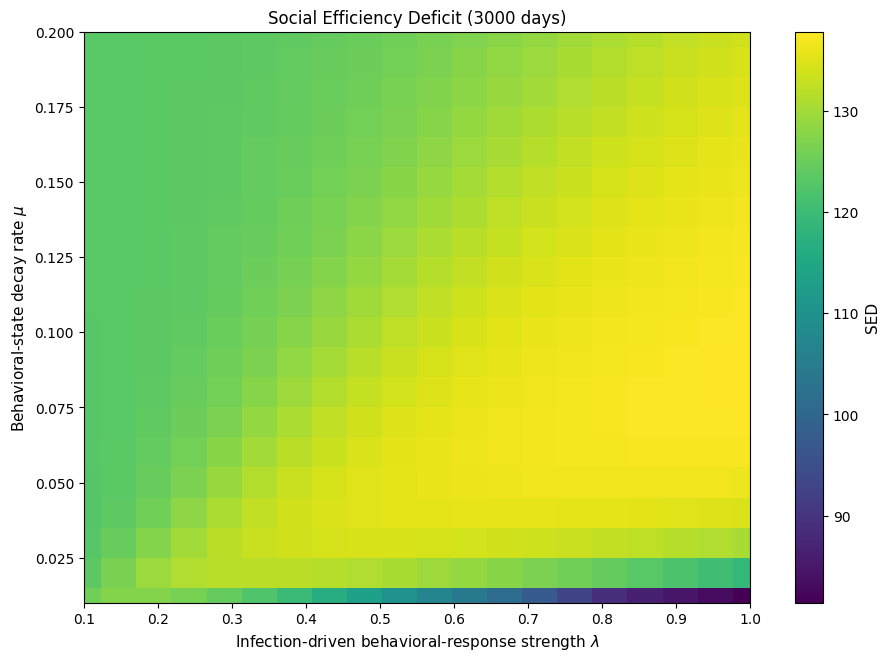

lm_SED: min=81.3770672, max=137.852236


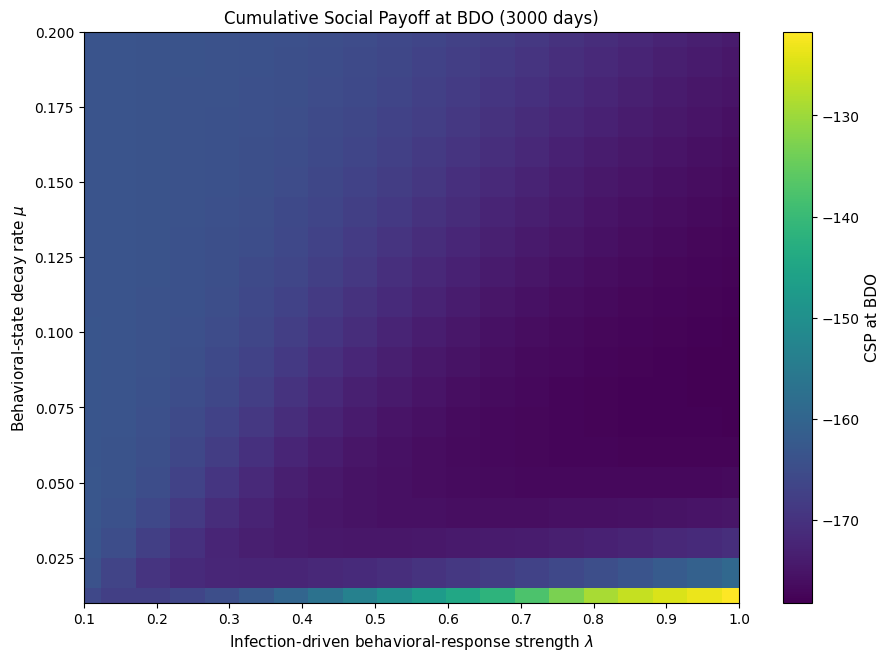

lm_CSP_BDO: min=-178.190943, max=-121.715774


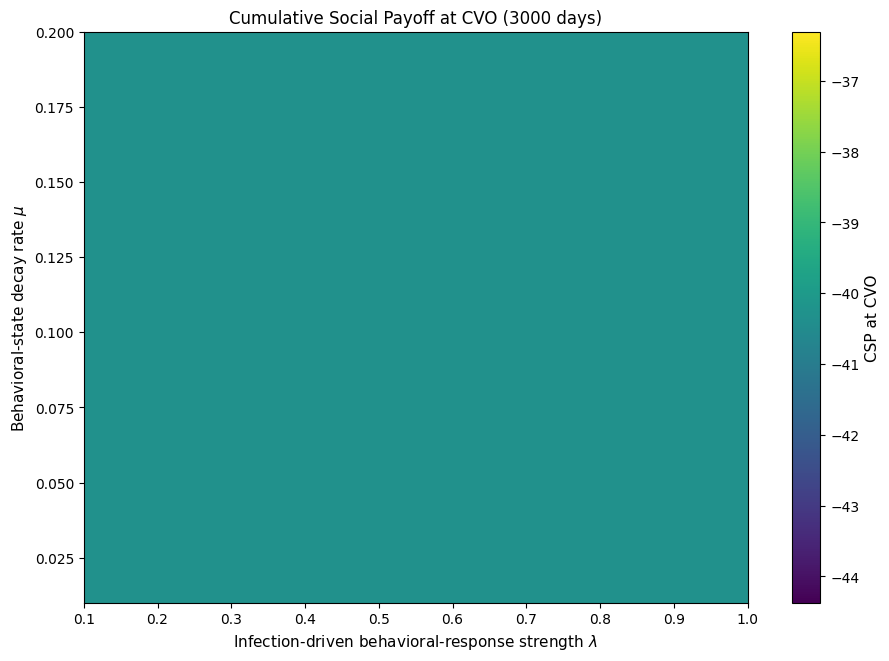

lm_CSP_CVO: min=-40.3387069, max=-40.3387069


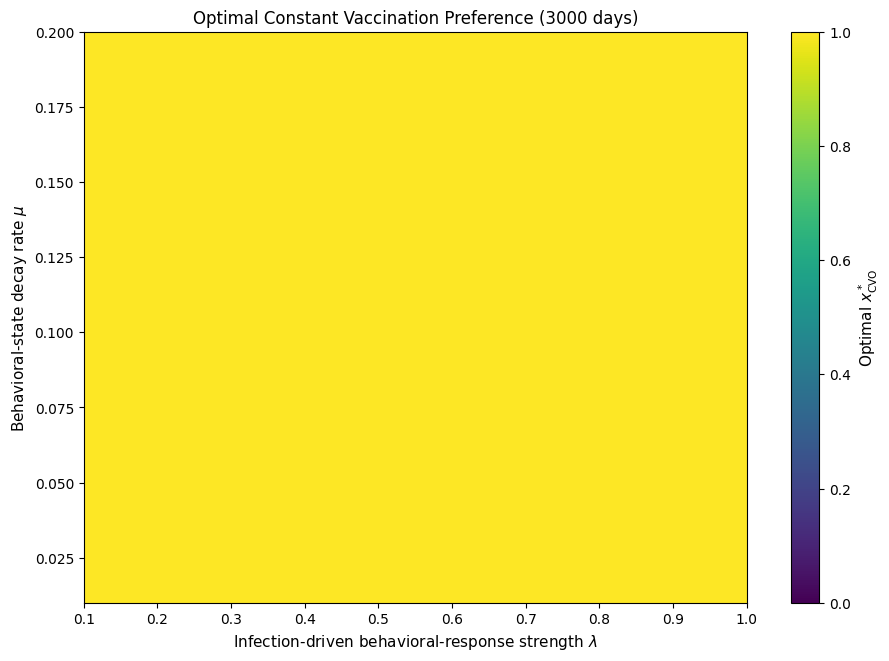

lm_optimal_x_CVO: min=1, max=1


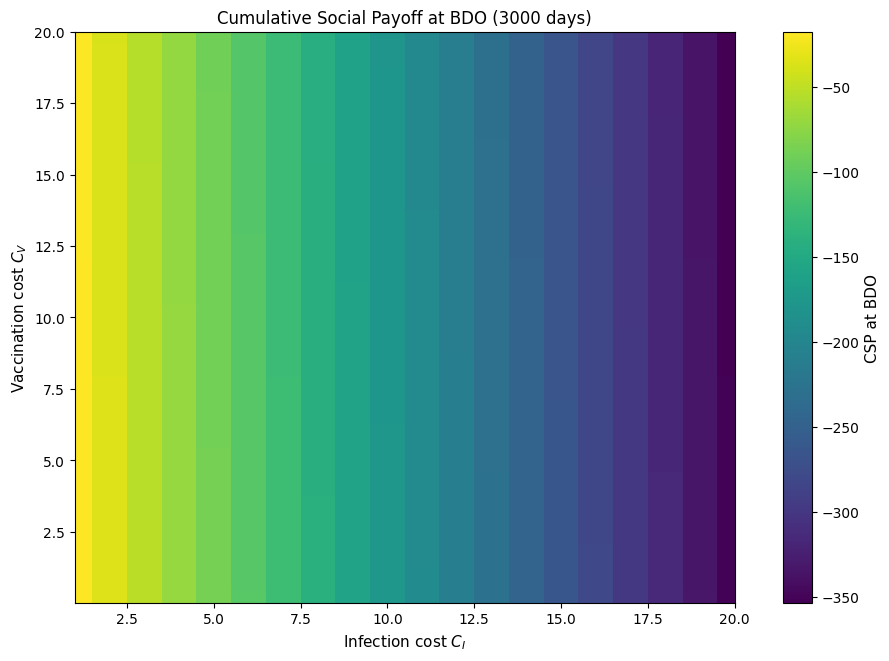

economic_CSP_BDO: min=-353.476462, max=-17.5681009


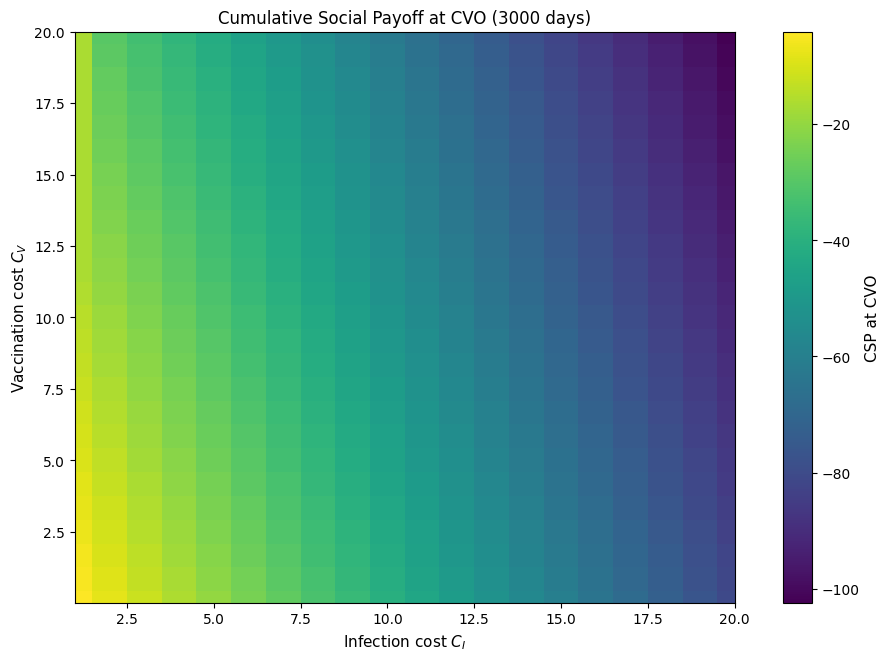

economic_CSP_CVO: min=-102.473275, max=-4.04260377


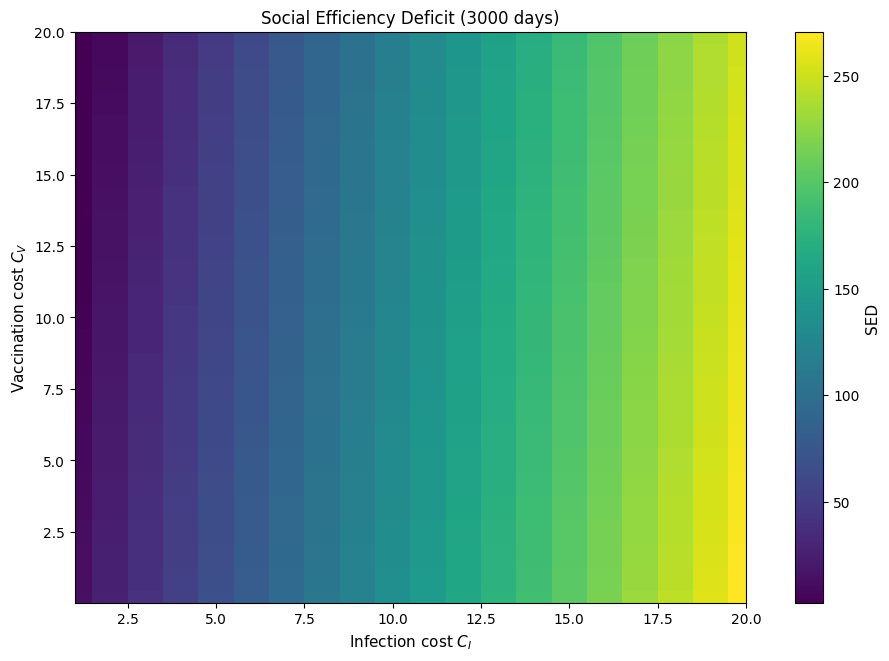

economic_SED: min=2.31459627, max=270.697128


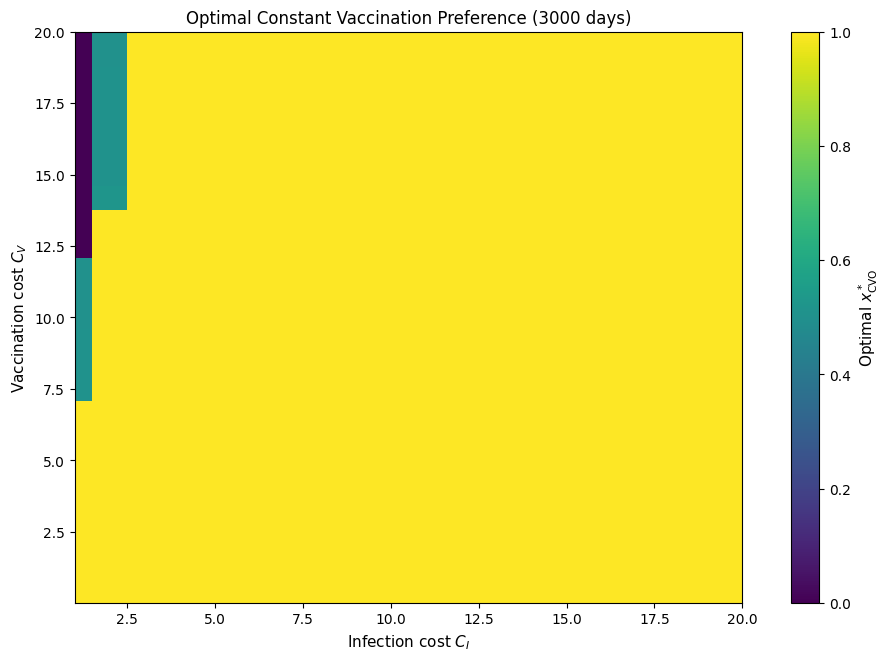

economic_optimal_x_CVO: min=0, max=1

All eight heatmaps generated successfully.
Figures saved in: /content/final_heatmaps


In [5]:

# ============================================================
# FINAL HEATMAPS — BEHAVIORAL SEIRS VACCINATION MODEL
#
# Numerical settings used to generate the data:
# Method: DOP853
# rtol = 1e-9
# atol = 1e-11
# Simulation horizon: 3000 days
#
# Outputs:
# 1–4: Behavioral parameter heatmaps (lambda, mu)
# 5–8: Economic parameter heatmaps (C_I, C_V)
#
# Requirements: numpy, matplotlib
# Run after the convergence-comparison cell.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. LOAD VALIDATED RESULTS
# ------------------------------------------------------------

OUTPUT_DIR = Path("final_heatmaps")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if "results" in globals() and 1e-9 in results:
    final = results[1e-9]
else:
    # Use this if running in a fresh notebook/session.
    # Upload the saved .npz file first.
    final = np.load("convergence_rtol_1e-09.npz")

# ------------------------------------------------------------
# 2. PARAMETER GRIDS
# ------------------------------------------------------------

lambda_values = np.linspace(0.1, 1.0, 20)
mu_values = np.linspace(0.01, 0.2, 20)

CI_values = np.linspace(1, 20, 20)
CV_values = np.linspace(0.01, 20, 25)

# ------------------------------------------------------------
# 3. CORRECT TERMINOLOGY
# ------------------------------------------------------------

LM_X = (
    r"Infection-driven behavioral-response strength $\lambda$"
)

LM_Y = (
    r"Behavioral-state decay rate $\mu$"
)

EC_X = r"Infection cost $C_I$"
EC_Y = r"Vaccination cost $C_V$"

# ------------------------------------------------------------
# 4. REUSABLE HEATMAP FUNCTION
# ------------------------------------------------------------

def make_heatmap(
    data,
    xs,
    ys,
    title,
    colorbar_label,
    xlabel,
    ylabel,
    filename,
    cmap="viridis",
    vmin=None,
    vmax=None
):
    data = np.asarray(data, dtype=float)

    expected_shape = (len(ys), len(xs))

    if data.shape != expected_shape:
        raise ValueError(
            f"{filename}: data shape {data.shape}, "
            f"expected {expected_shape}"
        )

    if not np.isfinite(data).all():
        raise ValueError(
            f"{filename}: non-finite values detected"
        )

    fig, ax = plt.subplots(
        figsize=(8.8, 6.5),
        constrained_layout=True
    )

    # Construct exact cell boundaries.
    x_edges = np.r_[
        xs[0] - (xs[1] - xs[0]) / 2,
        (xs[:-1] + xs[1:]) / 2,
        xs[-1] + (xs[-1] - xs[-2]) / 2
    ]

    y_edges = np.r_[
        ys[0] - (ys[1] - ys[0]) / 2,
        (ys[:-1] + ys[1:]) / 2,
        ys[-1] + (ys[-1] - ys[-2]) / 2
    ]

    im = ax.pcolormesh(
        x_edges,
        y_edges,
        data,
        shading="flat",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        rasterized=True
    )

    ax.set_xlim(xs[0], xs[-1])
    ax.set_ylim(ys[0], ys[-1])

    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=12)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(colorbar_label, fontsize=11)

    # Export both image and vector formats.
    for extension in ("png", "pdf"):
        fig.savefig(
            OUTPUT_DIR / f"{filename}.{extension}",
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()
    plt.close(fig)

    print(
        f"{filename}: "
        f"min={data.min():.9g}, "
        f"max={data.max():.9g}"
    )


# ============================================================
# 5. BEHAVIORAL PARAMETER HEATMAPS (LAMBDA, MU)
# ============================================================

# HEATMAP 1 — SOCIAL EFFICIENCY DEFICIT

make_heatmap(
    data=final["SED"],
    xs=lambda_values,
    ys=mu_values,
    title="Social Efficiency Deficit (3000 days)",
    colorbar_label="SED",
    xlabel=LM_X,
    ylabel=LM_Y,
    filename="lm_SED"
)


# HEATMAP 2 — CUMULATIVE SOCIAL PAYOFF AT BDO

make_heatmap(
    data=final["BDO"],
    xs=lambda_values,
    ys=mu_values,
    title="Cumulative Social Payoff at BDO (3000 days)",
    colorbar_label="CSP at BDO",
    xlabel=LM_X,
    ylabel=LM_Y,
    filename="lm_CSP_BDO"
)


# HEATMAP 3 — CUMULATIVE SOCIAL PAYOFF AT CVO
#
# CVO does not depend on lambda or mu.
# Therefore, a constant-color heatmap is expected.

make_heatmap(
    data=final["CVO"],
    xs=lambda_values,
    ys=mu_values,
    title="Cumulative Social Payoff at CVO (3000 days)",
    colorbar_label="CSP at CVO",
    xlabel=LM_X,
    ylabel=LM_Y,
    filename="lm_CSP_CVO"
)


# HEATMAP 4 — OPTIMAL CONSTANT VACCINATION PREFERENCE
#
# Under baseline economic costs, x_CVO* = 1.
# This is constant throughout the lambda-mu sweep.

make_heatmap(
    data=np.ones_like(final["CVO"]),
    xs=lambda_values,
    ys=mu_values,
    title="Optimal Constant Vaccination Preference (3000 days)",
    colorbar_label=r"Optimal $x_{\mathrm{CVO}}^*$",
    xlabel=LM_X,
    ylabel=LM_Y,
    filename="lm_optimal_x_CVO",
    vmin=0,
    vmax=1
)


# ============================================================
# 6. ECONOMIC PARAMETER HEATMAPS (C_I, C_V)
# ============================================================

# HEATMAP 5 — CUMULATIVE SOCIAL PAYOFF AT BDO

make_heatmap(
    data=final["econ_BDO"],
    xs=CI_values,
    ys=CV_values,
    title="Cumulative Social Payoff at BDO (3000 days)",
    colorbar_label="CSP at BDO",
    xlabel=EC_X,
    ylabel=EC_Y,
    filename="economic_CSP_BDO"
)


# HEATMAP 6 — CUMULATIVE SOCIAL PAYOFF AT CVO

make_heatmap(
    data=final["econ_CVO"],
    xs=CI_values,
    ys=CV_values,
    title="Cumulative Social Payoff at CVO (3000 days)",
    colorbar_label="CSP at CVO",
    xlabel=EC_X,
    ylabel=EC_Y,
    filename="economic_CSP_CVO"
)


# HEATMAP 7 — SOCIAL EFFICIENCY DEFICIT

make_heatmap(
    data=final["econ_SED"],
    xs=CI_values,
    ys=CV_values,
    title="Social Efficiency Deficit (3000 days)",
    colorbar_label="SED",
    xlabel=EC_X,
    ylabel=EC_Y,
    filename="economic_SED"
)


# HEATMAP 8 — OPTIMAL CONSTANT VACCINATION PREFERENCE

make_heatmap(
    data=final["econ_x"],
    xs=CI_values,
    ys=CV_values,
    title="Optimal Constant Vaccination Preference (3000 days)",
    colorbar_label=r"Optimal $x_{\mathrm{CVO}}^*$",
    xlabel=EC_X,
    ylabel=EC_Y,
    filename="economic_optimal_x_CVO",
    vmin=0,
    vmax=1
)


# ============================================================
# 7. COMPLETION
# ============================================================

print("\nAll eight heatmaps generated successfully.")
print(f"Figures saved in: {OUTPUT_DIR.resolve()}")


In [6]:
np.savez(
    "convergence_rtol_1e-09.npz",
    **results[1e-9]
)

In [7]:
def calculate_CSP_time_series(S, I, x, phi, CI, CV):
    """
    Corrected CSP:
    infection cost + actual vaccination flow cost.
    """
    I_frac = I / N
    vaccination_flow_frac = phi * x * S / N

    CSP_t = -CI * I_frac - CV * vaccination_flow_frac
    return CSP_t

def calculate_total_CSP(t, CSP_t):
    return np.trapezoid(CSP_t, t)


In [8]:
# 3. Run BDO simulation
# =====================================================

sol_BDO = solve_ivp(
    model_BDO,
    [t_start, t_end],
    y0,
    args=(params,),
    t_eval=t_eval,
    method="DOP853",
rtol=1e-9,
atol=1e-11
)

S_BDO, V_BDO, E_BDO, I_BDO, RN_BDO, RV_BDO, T_BDO = sol_BDO.y
x_BDO = sigmoid_trust(T_BDO, params["k"], params["Tc"])
CSP_BDO_t = calculate_CSP_time_series(
    S_BDO, I_BDO, x_BDO, params["phi"], CI, CV
)

CSP_BDO_total = calculate_total_CSP(sol_BDO.t, CSP_BDO_t)


In [9]:
# 4. Search CVO
# =====================================================

x_grid = np.linspace(0, 1, 101)

best_CSP_CVO = -np.inf
best_x_CVO = None
best_sol_CVO = None
best_CSP_CVO_t = None

for x_const in x_grid:
    sol_CVO = solve_ivp(
        model_constant_x,
        [t_start, t_end],
        y0,
        args=(params, x_const),
        t_eval=t_eval,
        method="DOP853",
rtol=1e-9,
atol=1e-11
    )

    S_CVO = sol_CVO.y[0]
    I_CVO = sol_CVO.y[3]
    x_CVO_arr = np.full_like(I_CVO, x_const)
    CSP_CVO_t = calculate_CSP_time_series(
        S_CVO, I_CVO, x_CVO_arr, params["phi"], CI, CV
    )

    CSP_CVO_total_temp = calculate_total_CSP(sol_CVO.t, CSP_CVO_t)

    if CSP_CVO_total_temp > best_CSP_CVO:
        best_CSP_CVO = CSP_CVO_total_temp
        best_x_CVO = x_const
        best_sol_CVO = sol_CVO
        best_CSP_CVO_t = CSP_CVO_t

CSP_CVO_total = best_CSP_CVO
SED = CSP_CVO_total - CSP_BDO_total

In [10]:
# 5. Create time-series dataframe
# =====================================================

S_CVO_best, V_CVO_best, E_CVO_best, I_CVO_best, RN_CVO_best, RV_CVO_best, T_CVO_best = best_sol_CVO.y
x_CVO_best = np.full_like(I_CVO_best, best_x_CVO)
time_series_df = pd.DataFrame({
    "Time_days": sol_BDO.t,

    "S_BDO": S_BDO,
    "V_BDO": V_BDO,
    "E_BDO": E_BDO,
    "I_BDO": I_BDO,
    "RN_BDO": RN_BDO,
    "RV_BDO": RV_BDO,
    "T_BDO": T_BDO,
    "x_BDO": x_BDO,
    "CSP_BDO_t": CSP_BDO_t,

    "S_CVO": S_CVO_best,
    "V_CVO": V_CVO_best,
    "E_CVO": E_CVO_best,
    "I_CVO": I_CVO_best,
    "RN_CVO": RN_CVO_best,
    "RV_CVO": RV_CVO_best,
    "x_CVO": x_CVO_best,
    "CSP_CVO_t": best_CSP_CVO_t
})

print("\n==============================")
print("TIME SERIES DATAFRAME INFO")
print("==============================")
print("Shape (rows, columns):", time_series_df.shape)
print("\nColumn names:")
print(time_series_df.columns.tolist())

print("\nFirst 10 rows:")
print(time_series_df.head(10))

print("\nLast 10 rows:")
print(time_series_df.tail(10))

print("\n==============================")
print("CSP AND SED RESULTS")
print("==============================")
print("CSP at BDO =", CSP_BDO_total)
print("Best x for CVO =", best_x_CVO)
print("CSP at CVO =", CSP_CVO_total)
print("SED = CSP_CVO - CSP_BDO =", SED)



TIME SERIES DATAFRAME INFO
Shape (rows, columns): (2000, 18)

Column names:
['Time_days', 'S_BDO', 'V_BDO', 'E_BDO', 'I_BDO', 'RN_BDO', 'RV_BDO', 'T_BDO', 'x_BDO', 'CSP_BDO_t', 'S_CVO', 'V_CVO', 'E_CVO', 'I_CVO', 'RN_CVO', 'RV_CVO', 'x_CVO', 'CSP_CVO_t']

First 10 rows:
   Time_days          S_BDO         V_BDO       E_BDO       I_BDO      RN_BDO  \
0   0.000000  999900.000000      0.000000    0.000000  100.000000    0.000000   
1   1.500750  996413.551958   3404.782896   67.823150   86.607053   14.832925   
2   3.001501  993565.809012   6172.686202  113.453466   94.172441   31.641524   
3   4.502251  991245.790917   8400.665343  155.318786  113.605702   53.267317   
4   6.003002  989345.466954  10187.660919  202.124309  142.241026   82.158966   
5   7.503752  987767.256521  11623.169167  259.083647  180.229287  120.818367   
6   9.004502  986427.003720  12782.452360  330.492551  229.172357  172.125548   
7  10.505253  985253.424654  13726.045783  420.878177  291.667321  239.603050   

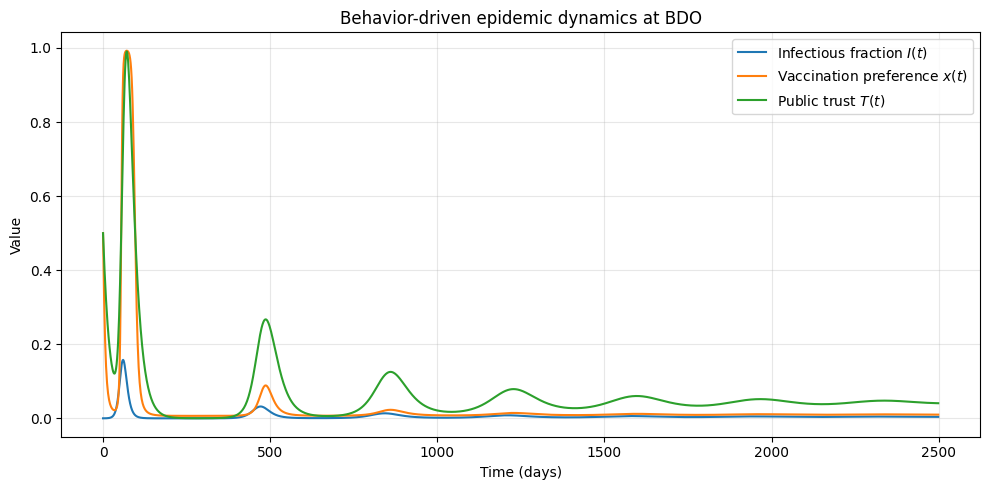

In [11]:
plot_end = 2500
mask = sol_BDO.t <= plot_end

plt.figure(figsize=(10, 5))
plt.plot(sol_BDO.t[mask], I_BDO[mask] / N, label="Infectious fraction $I(t)$")
plt.plot(sol_BDO.t[mask], x_BDO[mask], label="Vaccination preference $x(t)$")
plt.plot(sol_BDO.t[mask], T_BDO[mask], label="Public trust $T(t)$")

plt.xlabel("Time (days)")
plt.ylabel("Value")
plt.title("Behavior-driven epidemic dynamics at BDO")
#plt.ylim(0, 0.3)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

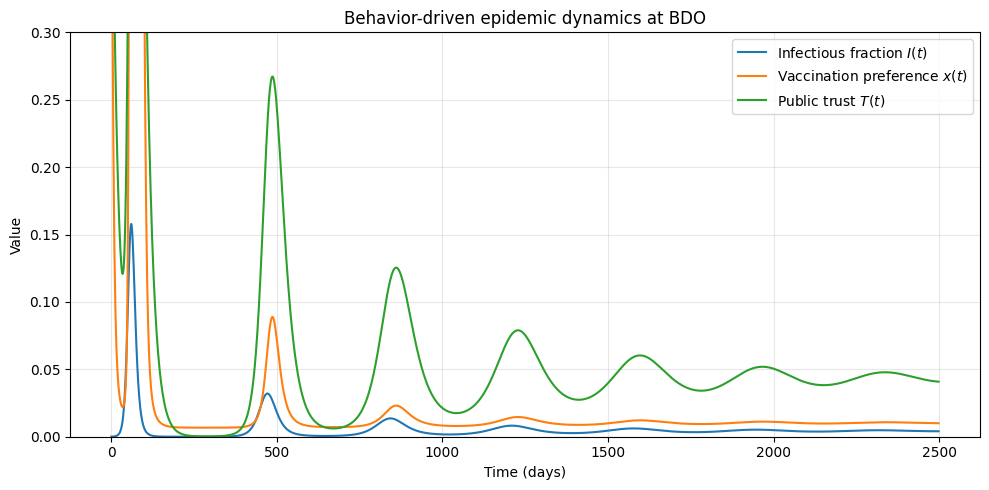

In [12]:
plot_end = 2500
mask = sol_BDO.t <= plot_end

plt.figure(figsize=(10, 5))
plt.plot(sol_BDO.t[mask], I_BDO[mask] / N, label="Infectious fraction $I(t)$")
plt.plot(sol_BDO.t[mask], x_BDO[mask], label="Vaccination preference $x(t)$")
plt.plot(sol_BDO.t[mask], T_BDO[mask], label="Public trust $T(t)$")

plt.xlabel("Time (days)")
plt.ylabel("Value")
plt.title("Behavior-driven epidemic dynamics at BDO")
plt.ylim(0, 0.3)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

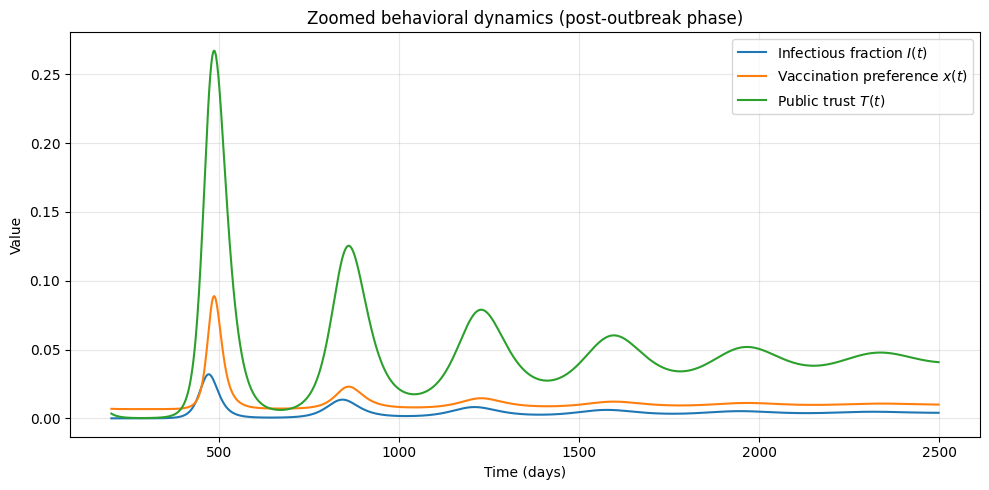

In [13]:
zoom_start = 200
zoom_end = 2500

mask_zoom = (sol_BDO.t >= zoom_start) & (sol_BDO.t <= zoom_end)

plt.figure(figsize=(10, 5))
plt.plot(sol_BDO.t[mask_zoom], I_BDO[mask_zoom] / N, label=r"Infectious fraction $I(t)$")
plt.plot(sol_BDO.t[mask_zoom], x_BDO[mask_zoom], label=r"Vaccination preference $x(t)$")
plt.plot(sol_BDO.t[mask_zoom], T_BDO[mask_zoom], label=r"Public trust $T(t)$")

plt.xlabel("Time (days)")
plt.ylabel("Value")
plt.title("Zoomed behavioral dynamics (post-outbreak phase)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

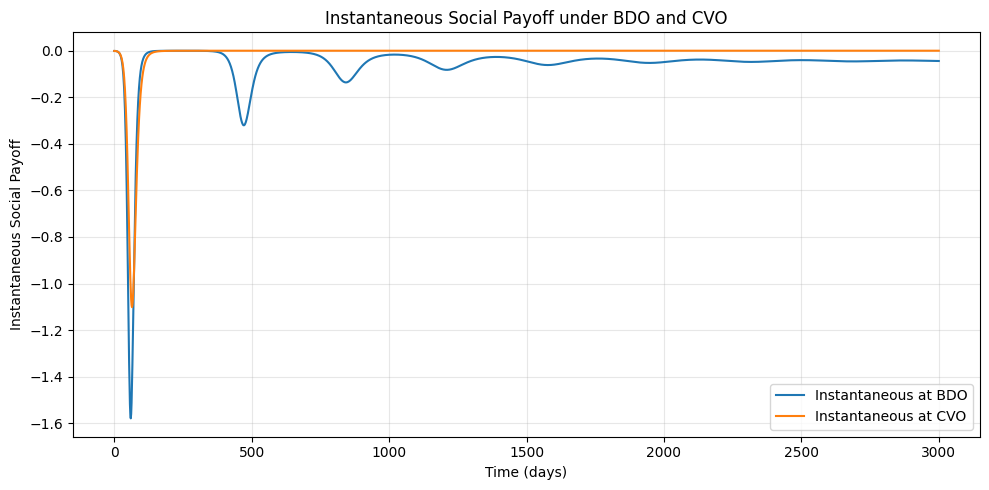

In [14]:
# 7. Plot CSP time series
# =====================================================

plt.figure(figsize=(10, 5))
plt.plot(sol_BDO.t, CSP_BDO_t, label="Instantaneous at BDO")
plt.plot(best_sol_CVO.t, best_CSP_CVO_t, label="Instantaneous at CVO")
plt.xlabel("Time (days)")

plt.ylabel("Instantaneous Social Payoff")
plt.title("Instantaneous Social Payoff under BDO and CVO")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:

import numpy as np
from scipy.integrate import solve_ivp

# =====================================================
# 1. Model parameters
# =====================================================

N = 1_000_000

p = dict(
    beta=0.6,
    phi=0.005,
    eps=0.8,
    sigma=0.25,
    gamma=0.2,
    omegaV=1/365,
    omegaN=1/730,
    lam=0.5,
    mu=0.05,
    k=10,
    Tc=0.5
)

# Initial conditions: S, V, E, I, RN, RV, T
y0 = [999900, 0, 0, 100, 0, 0, 0.5]

# Simulation horizon and economic parameters
t_final = 3000
C_I = 10.0
C_V = 0.02


# =====================================================
# 2. Epidemic model
# =====================================================

def rhs(t, y, xconst=None):

    S, V, E, I, RN, RV, T = y

    if xconst is None:
        x = 1 / (1 + np.exp(-p["k"] * (T - p["Tc"])))
    else:
        x = xconst

    beta = p["beta"]
    phi = p["phi"]
    eps = p["eps"]
    sigma = p["sigma"]
    gamma = p["gamma"]
    omegaV = p["omegaV"]
    omegaN = p["omegaN"]

    dS = (
        -beta * S * I / N
        -phi * x * S
        +omegaN * RN
        +omegaV * RV
    )

    dV = (
        phi * x * S
        -(1 - eps) * beta * V * I / N
    )

    dE = (
        beta * S * I / N
        +(1 - eps) * beta * V * I / N
        -sigma * E
    )

    dI = sigma * E - gamma * I

    dRN = (1 - x) * gamma * I - omegaN * RN

    dRV = x * gamma * I - omegaV * RV

    dT = p["lam"] * I / N - p["mu"] * T

    return [dS, dV, dE, dI, dRN, dRV, dT]


# =====================================================
# 3. CSP calculation
# =====================================================

def calculate_csp(rtol, n_points, xconst=None):

    t_eval = np.linspace(0, t_final, n_points)

    atol = rtol / 100

    sol = solve_ivp(
        lambda t, y: rhs(t, y, xconst),
        (0, t_final),
        y0,
        method="RK45",
        t_eval=t_eval,
        rtol=rtol,
        atol=atol
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    S = sol.y[0]
    I = sol.y[3]
    T = sol.y[6]

    if xconst is None:
        x = 1 / (1 + np.exp(-p["k"] * (T - p["Tc"])))
    else:
        x = xconst

    # Instantaneous social payoff
    payoff = (
        -C_I * I / N
        -C_V * p["phi"] * x * S / N
    )

    # Cumulative social payoff
    CSP = np.trapezoid(payoff, t_eval)

    return CSP


# =====================================================
# 4. Numerical convergence experiment
# =====================================================

settings = [
    (1e-3, 1001),
    (1e-4, 2001),
    (1e-5, 4001),
    (1e-6, 8001),
    (1e-7, 16001)
]

x_grid = np.linspace(0, 1, 101)

results = []

for rtol, n_points in settings:

    print(f"Running rtol={rtol:.0e}, points={n_points}...")

    # Behavior-Driven Outcome
    CSP_BDO = calculate_csp(
        rtol=rtol,
        n_points=n_points,
        xconst=None
    )

    # Constant Vaccination Optimum
    cvo_payoffs = np.array([
        calculate_csp(
            rtol=rtol,
            n_points=n_points,
            xconst=float(x)
        )
        for x in x_grid
    ])

    best_index = np.argmax(cvo_payoffs)

    x_CVO_opt = x_grid[best_index]
    CSP_CVO = cvo_payoffs[best_index]

    # Social Efficiency Deficit
    SED = CSP_CVO - CSP_BDO

    delta_t = t_final / (n_points - 1)

    results.append((
        rtol,
        delta_t,
        CSP_BDO,
        CSP_CVO,
        SED,
        x_CVO_opt
    ))


# =====================================================
# 5. Print convergence table
# =====================================================

print("\nNUMERICAL CONVERGENCE RESULTS\n")

print(
    f"{'rtol':<12}"
    f"{'dt':<12}"
    f"{'CSP_BDO':<17}"
    f"{'CSP_CVO':<17}"
    f"{'SED':<17}"
    f"{'x_CVO*':<10}"
)

print("-" * 85)

for row in results:

    rtol, dt, bdo, cvo, sed, xopt = row

    print(
        f"{rtol:<12.0e}"
        f"{dt:<12.4f}"
        f"{bdo:<17.6f}"
        f"{cvo:<17.6f}"
        f"{sed:<17.6f}"
        f"{xopt:<10.2f}"
    )


# =====================================================
# 6. Difference between finest two configurations
# =====================================================

previous = results[-2]
finest = results[-1]

print("\nABSOLUTE DIFFERENCES BETWEEN FINEST TWO RUNS")

print(
    "CSP_BDO:",
    abs(finest[2] - previous[2])
)

print(
    "CSP_CVO:",
    abs(finest[3] - previous[3])
)

print(
    "SED:",
    abs(finest[4] - previous[4])
)

print(
    "Optimal x_CVO:",
    abs(finest[5] - previous[5])
)


Running rtol=1e-03, points=1001...
Running rtol=1e-04, points=2001...
Running rtol=1e-05, points=4001...
Running rtol=1e-06, points=8001...
Running rtol=1e-07, points=16001...

NUMERICAL CONVERGENCE RESULTS

rtol        dt          CSP_BDO          CSP_CVO          SED              x_CVO*    
-------------------------------------------------------------------------------------
1e-03       3.0000      -175.663014      -40.341295       135.321720       1.00      
1e-04       1.5000      -175.674282      -40.338948       135.335334       1.00      
1e-05       0.7500      -175.672434      -40.338700       135.333734       1.00      
1e-06       0.3750      -175.672466      -40.338675       135.333792       1.00      
1e-07       0.1875      -175.672456      -40.338671       135.333785       1.00      

ABSOLUTE DIFFERENCES BETWEEN FINEST TWO RUNS
CSP_BDO: 1.0192096596028932e-05
CSP_CVO: 3.6964014213936025e-06
SED: 6.49569517463533e-06
Optimal x_CVO: 0.0


INITIAL BEHAVIORAL STATE SENSITIVITY
Fixed lambda = 0.5

Scenario: T(0) = 0.0
Initial x(0): 0.00669285
First infection peak: 162632.4455
Day of first peak: 59.2500
Maximum x(t): 0.99320247
I(3000): 4434.145336
x(3000): 0.01034259

Scenario: T(0) = 0.5
Initial x(0): 0.50000000
First infection peak: 157881.2618
Day of first peak: 60.0000
Maximum x(t): 0.99267462
I(3000): 4416.783053
x(3000): 0.01032492

First peak reduction: 2.9214%


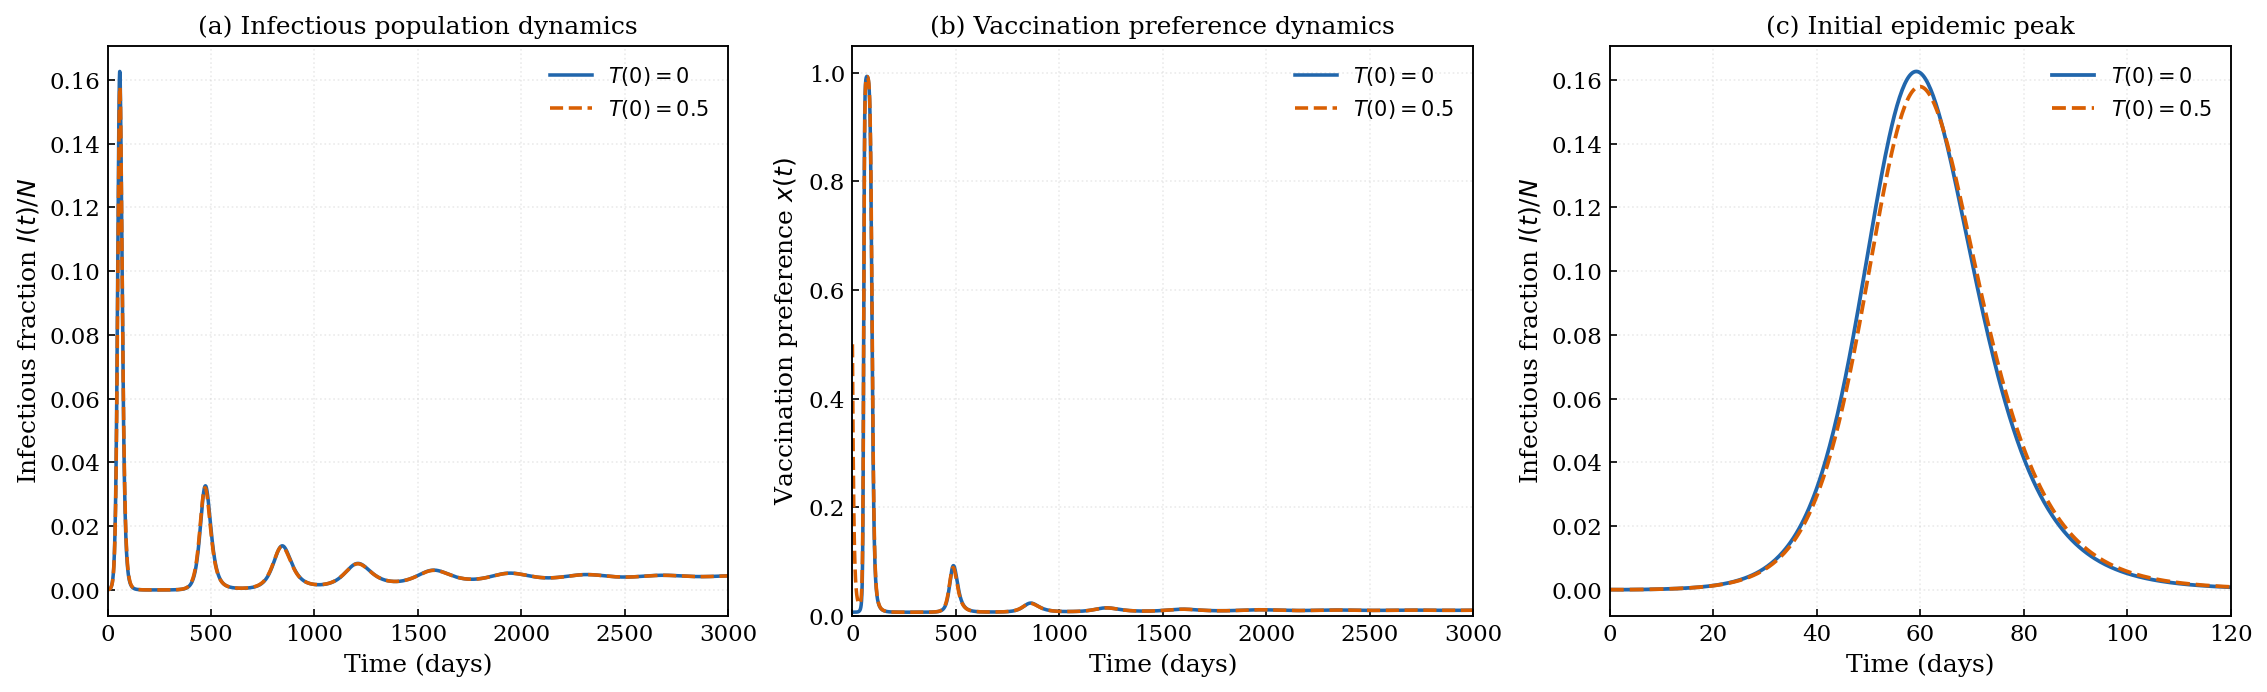

In [16]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# INITIAL BEHAVIORAL STATE SENSITIVITY ANALYSIS
# Original seven-dimensional epidemic model
# ============================================================

# Baseline parameters
N = 1_000_000
beta = 0.6
phi = 0.005
epsilon = 0.8
sigma = 0.25
gamma = 0.2

omega_V = 1 / 365
omega_N = 1 / (365 * 2)

lam = 0.5
mu = 0.05
k = 10
Tc = 0.5

# Simulation settings
t_end = 3000
t_eval = np.linspace(0, t_end, 12001)

def vaccination_preference(T):
    z = np.clip(k * (T - Tc), -700, 700)
    return 1 / (1 + np.exp(-z))


# Original model: no equations modified
def epidemic_model(t, y):
    S, V, E, I, RN, RV, T = y

    x = vaccination_preference(T)

    infection_S = beta * S * I / N
    infection_V = (1 - epsilon) * beta * V * I / N

    dS = (
        -infection_S
        - phi * x * S
        + omega_N * RN
        + omega_V * RV
    )

    dV = phi * x * S - infection_V

    dE = infection_S + infection_V - sigma * E

    dI = sigma * E - gamma * I

    dRN = (1 - x) * gamma * I - omega_N * RN

    dRV = x * gamma * I - omega_V * RV

    dT = lam * I / N - mu * T

    return [dS, dV, dE, dI, dRN, dRV, dT]


# Initial epidemiological conditions
S0 = 999_900
V0 = 0
E0 = 0
I0 = 100
RN0 = 0
RV0 = 0

initial_T_values = [0.0, 0.5]

results = {}

for T0 in initial_T_values:

    y0 = [S0, V0, E0, I0, RN0, RV0, T0]

    sol = solve_ivp(
        epidemic_model,
        (0, t_end),
        y0,
        method="DOP853",
        t_eval=t_eval,
        rtol=1e-9,
        atol=1e-11
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    I = sol.y[3]
    T = sol.y[6]
    x = vaccination_preference(T)

    results[T0] = {
        "time": sol.t,
        "I": I,
        "T": T,
        "x": x,
        "solution": sol
    }


# ============================================================
# Numerical comparison
# ============================================================

print("=" * 72)
print("INITIAL BEHAVIORAL STATE SENSITIVITY")
print("Fixed lambda = 0.5")
print("=" * 72)

for T0, data in results.items():

    time = data["time"]
    I = data["I"]
    x = data["x"]

    # First peak within the first 200 days
    early = time <= 200
    early_indices = np.where(early)[0]
    peak_idx = early_indices[np.argmax(I[early])]

    print(f"\nScenario: T(0) = {T0}")
    print(f"Initial x(0): {x[0]:.8f}")
    print(f"First infection peak: {I[peak_idx]:.4f}")
    print(f"Day of first peak: {time[peak_idx]:.4f}")
    print(f"Maximum x(t): {np.max(x):.8f}")
    print(f"I(3000): {I[-1]:.6f}")
    print(f"x(3000): {x[-1]:.8f}")

peak_0 = np.max(
    results[0.0]["I"][results[0.0]["time"] <= 200]
)
peak_05 = np.max(
    results[0.5]["I"][results[0.5]["time"] <= 200]
)

reduction = (peak_0 - peak_05) / peak_0 * 100

print("\n" + "=" * 72)
print(f"First peak reduction: {reduction:.4f}%")
print("=" * 72)


# ============================================================
# Publication-ready figure
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "axes.linewidth": 0.9
})

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    constrained_layout=True
)

colors = {
    0.0: "#2166AC",
    0.5: "#D95F02"
}

styles = {
    0.0: "-",
    0.5: "--"
}

labels = {
    0.0: r"$T(0)=0$",
    0.5: r"$T(0)=0.5$"
}

for T0, data in results.items():

    t = data["time"]
    I = data["I"]
    x = data["x"]

    # Panel (a): infectious population fraction
    axes[0].plot(
        t,
        I / N,
        color=colors[T0],
        linestyle=styles[T0],
        linewidth=1.7,
        label=labels[T0]
    )

    # Panel (b): vaccination preference
    axes[1].plot(
        t,
        x,
        color=colors[T0],
        linestyle=styles[T0],
        linewidth=1.7,
        label=labels[T0]
    )

    # Panel (c): initial infection peak
    axes[2].plot(
        t,
        I / N,
        color=colors[T0],
        linestyle=styles[T0],
        linewidth=1.8,
        label=labels[T0]
    )


axes[0].set_title(
    "(a) Infectious population dynamics"
)
axes[0].set_xlabel("Time (days)")
axes[0].set_ylabel(r"Infectious fraction $I(t)/N$")
axes[0].set_xlim(0, 3000)

axes[1].set_title(
    "(b) Vaccination preference dynamics"
)
axes[1].set_xlabel("Time (days)")
axes[1].set_ylabel(r"Vaccination preference $x(t)$")
axes[1].set_xlim(0, 3000)
axes[1].set_ylim(0, 1.05)

axes[2].set_title(
    "(c) Initial epidemic peak"
)
axes[2].set_xlabel("Time (days)")
axes[2].set_ylabel(r"Infectious fraction $I(t)/N$")
axes[2].set_xlim(0, 120)

for ax in axes:
    ax.grid(alpha=0.25, linestyle=":")
    ax.legend(frameon=False)
    ax.tick_params(direction="in")

plt.savefig(
    "Initial_Behavioral_State_Sensitivity.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "Initial_Behavioral_State_Sensitivity.png",
    bbox_inches="tight",
    dpi=600
)

plt.show()


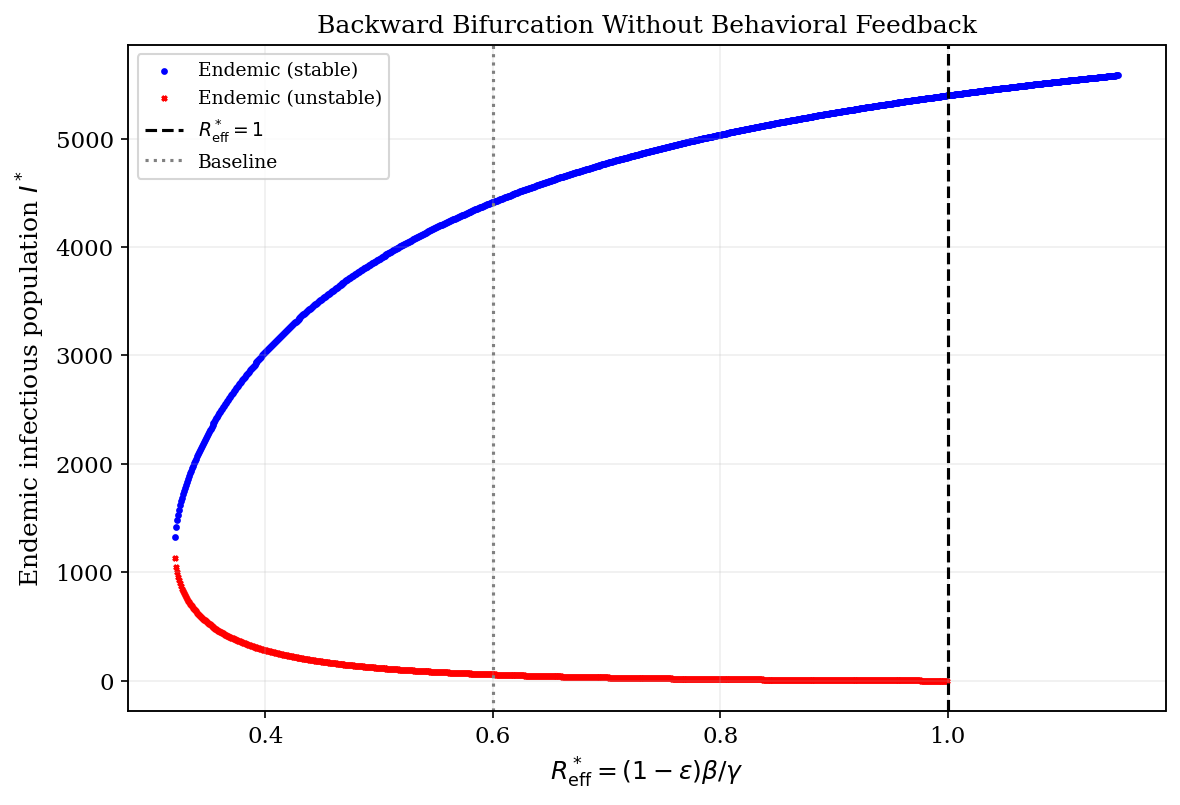


VACCINE-WANING SENSITIVITY TABLE


,duration_years,theta,Reff,DFE_stability,DFE_max_real_eig,positive_roots,endemic_I_values,endemic_stability
0,inf,0.000000,0.600000,stable,-0.000033,2,57.201734; 4412.584428,unstable; stable
1,1000.0,0.000003,0.781619,stable,-0.000036,2,33.781631; 4413.173482,unstable; stable
2,500.0,0.000005,0.937684,stable,-0.000039,2,10.367793; 4413.756269,unstable; stable
3,410.0,0.000007,0.999472,stable,-0.000040,2,0.090500; 4414.010174,unstable; stable
4,400.0,0.000007,1.007762,unstable,0.000861,1,4414.045345,stable
5,100.0,0.000027,1.680378,unstable,0.065936,1,4418.204766,stable
6,20.0,0.000137,2.528812,unstable,0.131463,1,4435.946838,stable
7,10.0,0.000274,2.738762,unstable,0.145895,1,4451.214109,stable
8,5.0,0.000548,2.861863,unstable,0.154102,1,4470.037064,stable


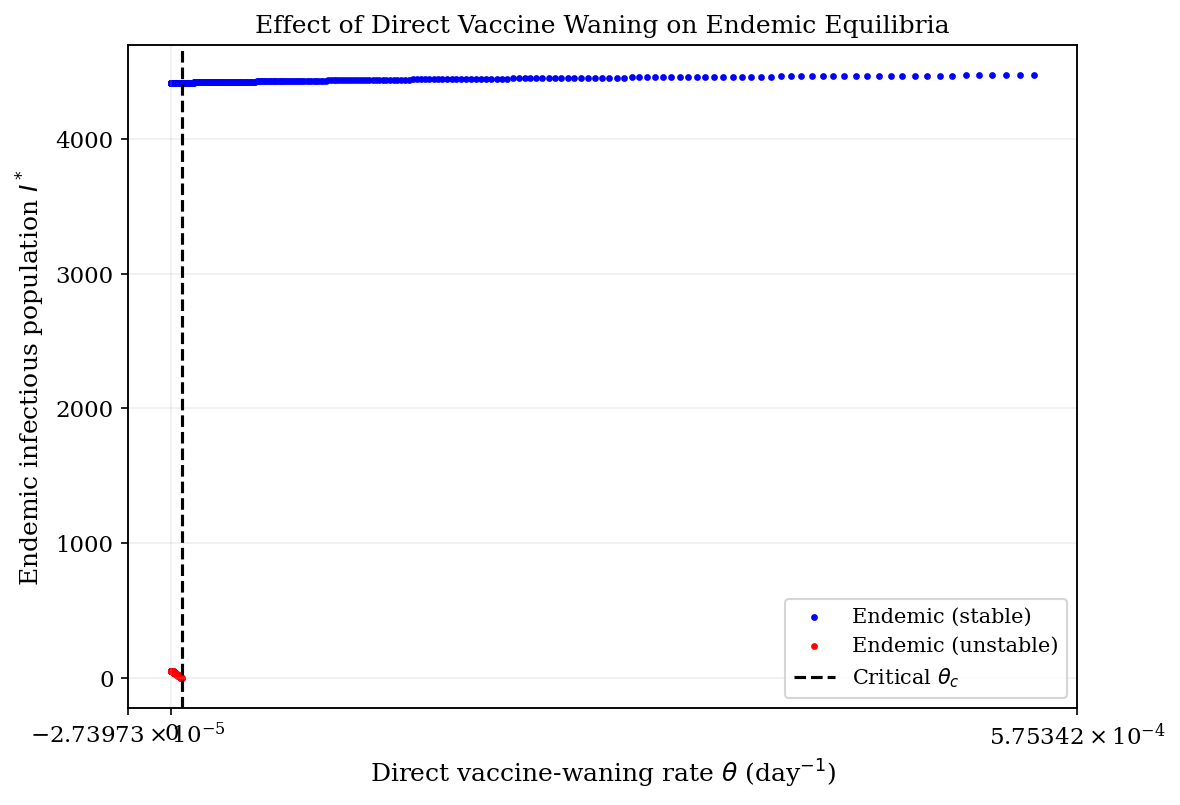

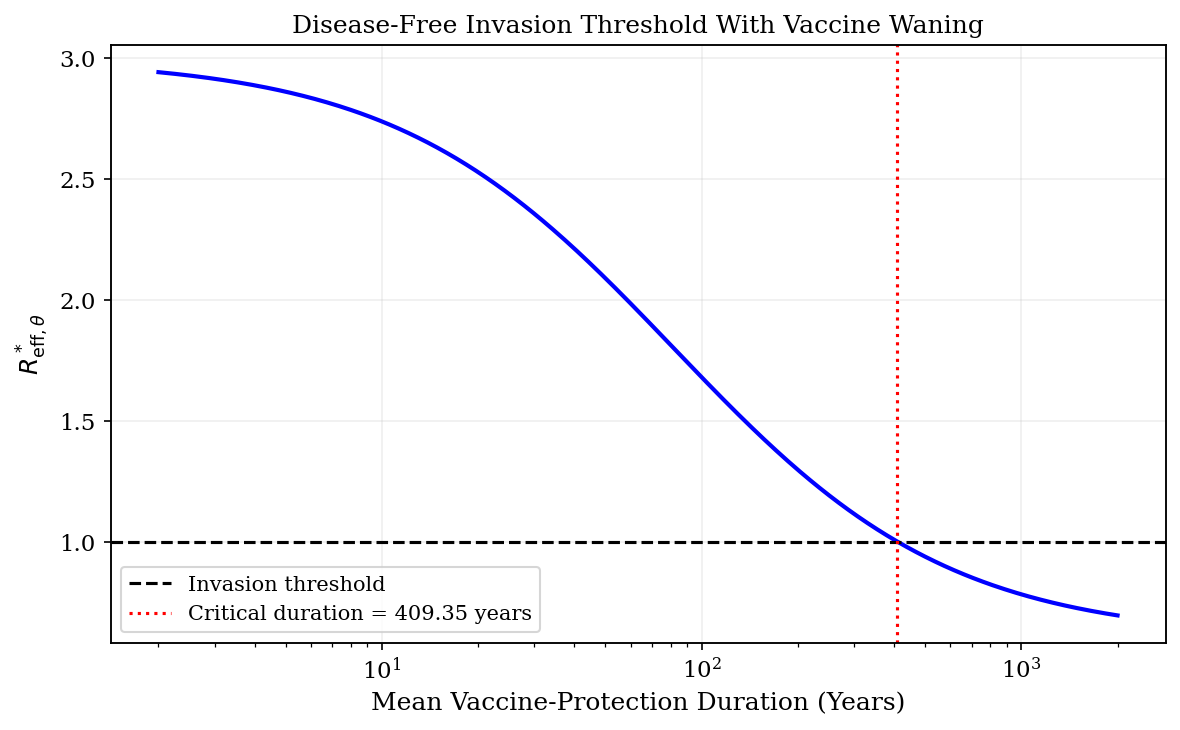

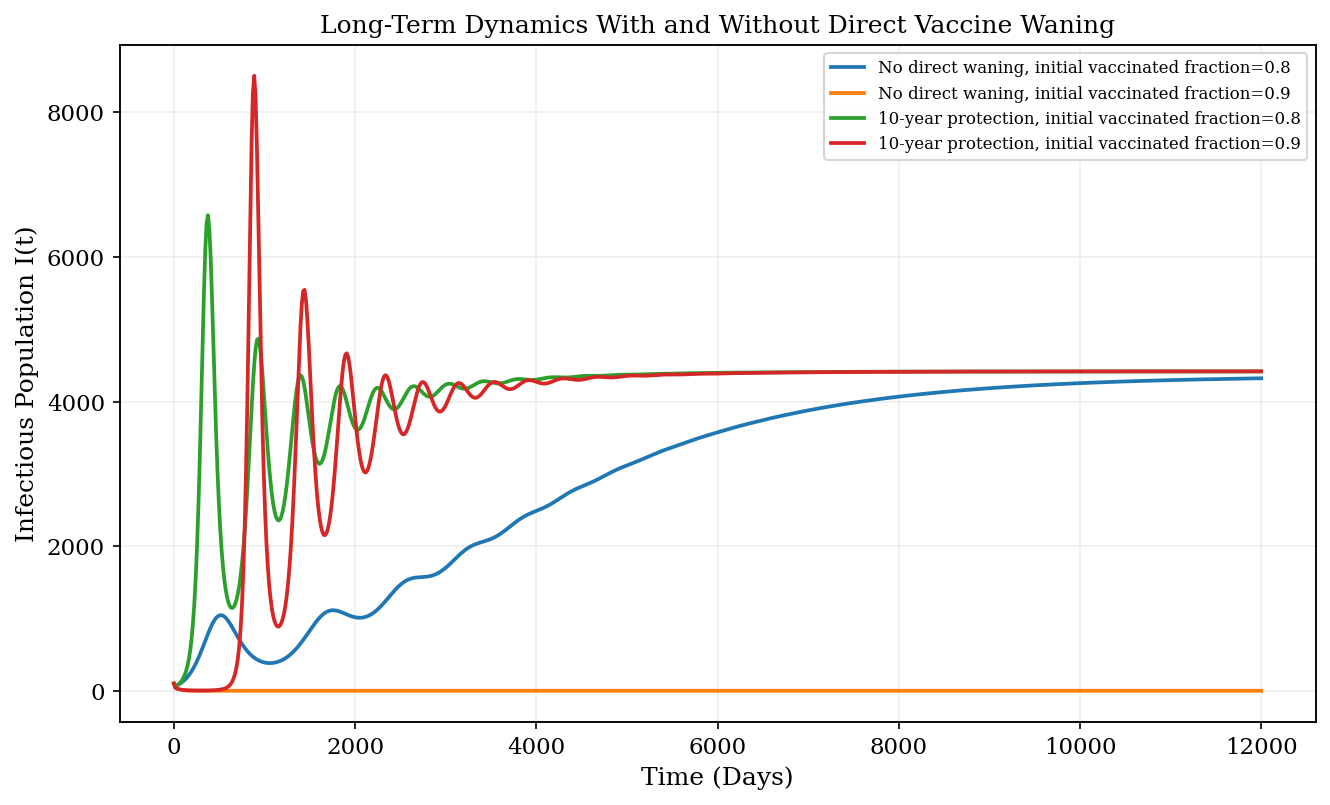


NUMERICAL VERIFICATION

Baseline vaccination preference:
x0 = 0.0066928509

No-feedback endemic equilibria:
Branch 1: I* = 57.201734, stability = unstable, max Re(eigenvalue) = 5.67572978e-04
Branch 2: I* = 4412.584428, stability = stable, max Re(eigenvalue) = -5.27769981e-04

Disease-free equilibrium:
Reff = 0.600000, stability = stable

Critical vaccine-waning threshold:
theta_c = 6.6928509243e-06 per day
Mean duration = 409.3511 years

Backward-bifurcation condition:
B at Reff=1 = -0.7950703331
Condition satisfied: True

ALL BASELINE CHECKS PASSED.

Figures and CSV files saved in:
/content/results


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

# ============================================================
# BACKWARD BIFURCATION AND VACCINE-WANING NUMERICAL CHECKS
# Trust-mediated vaccination epidemic model
#
# Google Colab compatible
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass, replace
from pathlib import Path
from scipy.optimize import brentq
from scipy.integrate import solve_ivp

# ------------------------------------------------------------
# 1. OUTPUT FOLDER AND BASELINE PARAMETERS
# ------------------------------------------------------------

OUT = Path("results")
OUT.mkdir(exist_ok=True)

@dataclass(frozen=True)
class Params:
    N: float = 1e6
    beta: float = 0.6
    epsilon: float = 0.8
    phi: float = 0.005
    sigma: float = 0.25
    gamma: float = 0.2
    omegaN: float = 1 / 730
    omegaV: float = 1 / 365
    k: float = 10
    Tc: float = 0.5
    mu: float = 0.05
    lam: float = 0.0
    theta: float = 0.0

p = Params()

# ------------------------------------------------------------
# 2. BEHAVIORAL FUNCTIONS
# ------------------------------------------------------------

def sigmoid(T, p):
    return 1 / (1 + np.exp(-p.k * (T - p.Tc)))

def x0(p):
    return sigmoid(0, p)

def H(x, p):
    return (
        1
        + p.gamma / p.sigma
        + p.gamma * (
            (1 - x) / p.omegaN
            + x / p.omegaV
        )
    )

# ------------------------------------------------------------
# 3. DISEASE-FREE EQUILIBRIUM AND INVASION THRESHOLD
# ------------------------------------------------------------

def dfe(p):
    x = x0(p)
    vaccination_rate = p.phi * x

    S = p.N * p.theta / (p.theta + vaccination_rate)
    V = p.N - S

    return np.array(
        [S, V, 0, 0, 0, 0, 0],
        dtype=float
    )

def Reff(p):
    vaccination_rate = p.phi * x0(p)

    return (
        p.beta / p.gamma
        * (
            p.theta
            + (1 - p.epsilon) * vaccination_rate
        )
        / (p.theta + vaccination_rate)
    )

def theta_critical(p):
    vaccination_rate = p.phi * x0(p)

    return (
        vaccination_rate
        * (
            p.gamma
            - (1 - p.epsilon) * p.beta
        )
        / (p.beta - p.gamma)
    )

# ------------------------------------------------------------
# 4. FULL EPIDEMIC-BEHAVIORAL MODEL
# ------------------------------------------------------------

def rhs(t, y, p):

    S, V, E, I, RN, RV, T = y

    x = sigmoid(T, p)
    force = p.beta * I / p.N

    dS = (
        -force * S
        - p.phi * x * S
        + p.omegaN * RN
        + p.omegaV * RV
        + p.theta * V
    )

    dV = (
        p.phi * x * S
        - (1 - p.epsilon) * force * V
        - p.theta * V
    )

    dE = (
        force * (S + (1 - p.epsilon) * V)
        - p.sigma * E
    )

    dI = p.sigma * E - p.gamma * I

    dRN = (
        (1 - x) * p.gamma * I
        - p.omegaN * RN
    )

    dRV = (
        x * p.gamma * I
        - p.omegaV * RV
    )

    dT = p.lam * I / p.N - p.mu * T

    return np.array(
        [dS, dV, dE, dI, dRN, dRV, dT]
    )

# ------------------------------------------------------------
# 5. POPULATION-REDUCED JACOBIAN
# ------------------------------------------------------------

def reduced_rhs(y, p):

    V, E, I, RN, RV, T = y

    S = p.N - V - E - I - RN - RV

    full_y = np.array(
        [S, V, E, I, RN, RV, T]
    )

    return rhs(0, full_y, p)[1:]


def jacobian(fun, y, p):

    # Complex-step numerical differentiation
    # avoids finite-difference cancellation errors.

    n = len(y)
    J = np.empty((n, n))

    for j in range(n):

        z = np.asarray(y, dtype=complex).copy()
        z[j] += 1e-25j

        J[:, j] = (
            np.imag(fun(z, p)) / 1e-25
        )

    return J


def classify(y, p):

    J = jacobian(reduced_rhs, y[1:], p)

    eigenvalues = np.linalg.eigvals(J)
    max_real = float(np.max(eigenvalues.real))

    if max_real < -1e-9:
        status = "stable"
    elif max_real > 1e-9:
        status = "unstable"
    else:
        status = "near-neutral"

    return status, max_real

# ------------------------------------------------------------
# 6. ENDEMIC EQUILIBRIUM AT LAMBDA = 0
# ------------------------------------------------------------

def endemic_from_i(i, p):

    x = x0(p)

    D = (
        p.theta
        + (1 - p.epsilon) * p.beta * i
    )

    if D <= 0:
        return None

    Sfrac = (
        p.gamma
        / (
            p.beta
            * (
                1
                + (1 - p.epsilon)
                * p.phi * x / D
            )
        )
    )

    Vfrac = p.phi * x * Sfrac / D

    Efrac = p.gamma / p.sigma * i

    RNfrac = (
        (1 - x) * p.gamma
        / p.omegaN * i
    )

    RVfrac = (
        x * p.gamma
        / p.omegaV * i
    )

    return p.N * np.array(
        [
            Sfrac,
            Vfrac,
            Efrac,
            i,
            RNfrac,
            RVfrac,
            0.0
        ]
    )


def conservation(i, p):

    y = endemic_from_i(i, p)

    if y is None:
        return np.nan

    return np.sum(y[:6]) / p.N - 1


def endemic_roots(p):

    assert p.lam == 0, (
        "This equilibrium routine is valid only for lambda=0."
    )

    x = x0(p)

    # Original model: exact quadratic
    if p.theta == 0:

        A = p.beta * H(x, p)

        B = (
            p.phi * x * H(x, p)
            + p.gamma
            - p.beta
        )

        C = (
            p.phi * x
            * (
                p.gamma
                / ((1 - p.epsilon) * p.beta)
                - 1
            )
        )

        roots = np.roots([A, B, C])

        values = sorted(
            float(z.real)
            for z in roots
            if abs(z.imag) < 1e-9
            and z.real > 1e-12
        )

        return [
            endemic_from_i(i, p)
            for i in values
        ]

    # Extended model: numerical root search
    grid = np.r_[
        0,
        np.geomspace(1e-13, 0.999, 2500)
    ]

    values = []

    for left, right in zip(
        grid[:-1], grid[1:]
    ):

        fl = conservation(left, p)
        fr = conservation(right, p)

        if (
            np.isfinite(fl)
            and np.isfinite(fr)
            and fl * fr < 0
        ):

            root = brentq(
                conservation,
                left,
                right,
                args=(p,),
                xtol=1e-15
            )

            if (
                not values
                or abs(root - values[-1]) > 1e-9
            ):
                values.append(root)

    return [
        endemic_from_i(i, p)
        for i in values
    ]


def savefig(name):

    plt.tight_layout()

    plt.savefig(
        OUT / (name + ".png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        OUT / (name + ".pdf"),
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ============================================================
# FIGURE 1: BACKWARD BIFURCATION AT LAMBDA = 0
# ============================================================

base = replace(
    p,
    lam=0,
    theta=0
)

betas = np.linspace(
    0.12, 1.15, 1200
)

branches = []

for beta in betas:

    q = replace(
        base,
        beta=float(beta)
    )

    for y in endemic_roots(q):

        status, eig = classify(y, q)

        branches.append({
            "beta": beta,
            "R_eff": Reff(q),
            "I": y[3],
            "stability": status,
            "max_real_eig": eig
        })

branch_df = pd.DataFrame(branches)

branch_df.to_csv(
    OUT / "backward_branches.csv",
    index=False
)

fig, ax = plt.subplots(
    figsize=(8, 5.5)
)

for status, color, marker in [
    ("stable", "blue", "o"),
    ("unstable", "red", "x")
]:

    df = branch_df[
        branch_df.stability == status
    ]

    ax.scatter(
        df.R_eff,
        df.I,
        s=5,
        color=color,
        marker=marker,
        label=f"Endemic ({status})"
    )

ax.axvline(
    1,
    color="black",
    linestyle="--",
    label=r"$R_{\mathrm{eff}}^*=1$"
)

ax.axvline(
    Reff(base),
    color="gray",
    linestyle=":",
    label="Baseline"
)

ax.set_xlabel(
    r"$R_{\mathrm{eff}}^*=(1-\epsilon)\beta/\gamma$"
)

ax.set_ylabel(
    r"Endemic infectious population $I^*$"
)

ax.set_title(
    "Backward Bifurcation Without Behavioral Feedback"
)

ax.legend(fontsize=9)
ax.grid(alpha=0.2)

savefig("fig1_backward_bifurcation")

# ============================================================
# FIGURE 2: VACCINE-WANING SENSITIVITY
# ============================================================

threshold = theta_critical(base)

durations = [
    np.inf,
    1000,
    500,
    410,
    400,
    100,
    20,
    10,
    5
]

rows = []

for years in durations:

    if np.isinf(years):
        theta = 0
    else:
        theta = 1 / (365 * years)

    q = replace(
        base,
        theta=theta
    )

    equilibria = endemic_roots(q)

    dfe_status, dfe_eig = classify(
        dfe(q), q
    )

    rows.append({
        "duration_years": years,
        "theta": theta,
        "Reff": Reff(q),
        "DFE_stability": dfe_status,
        "DFE_max_real_eig": dfe_eig,
        "positive_roots": len(equilibria),
        "endemic_I_values": "; ".join(
            f"{y[3]:.6f}"
            for y in equilibria
        ),
        "endemic_stability": "; ".join(
            classify(y, q)[0]
            for y in equilibria
        )
    })

waning_df = pd.DataFrame(rows)

waning_df.to_csv(
    OUT / "waning_sensitivity.csv",
    index=False
)

print("\nVACCINE-WANING SENSITIVITY TABLE")
display(waning_df)

thetas = np.r_[
    0,
    np.geomspace(
        1e-9,
        1 / (365 * 5),
        800
    )
]

waning = []

for theta in thetas:

    q = replace(
        base,
        theta=float(theta)
    )

    for y in endemic_roots(q):

        status, eig = classify(y, q)

        waning.append({
            "theta": theta,
            "I": y[3],
            "stability": status,
            "max_real_eig": eig
        })

waning_branches = pd.DataFrame(waning)

waning_branches.to_csv(
    OUT / "waning_branches.csv",
    index=False
)

fig, ax = plt.subplots(
    figsize=(8, 5.5)
)

for status, color in [
    ("stable", "blue"),
    ("unstable", "red")
]:

    df = waning_branches[
        waning_branches.stability == status
    ]

    ax.scatter(
        df.theta,
        df.I,
        s=5,
        color=color,
        label=f"Endemic ({status})"
    )

ax.axvline(
    threshold,
    color="black",
    linestyle="--",
    label=r"Critical $\theta_c$"
)

ax.set_xscale("symlog")

ax.set_xlabel(
    r"Direct vaccine-waning rate $\theta$ (day$^{-1}$)"
)

ax.set_ylabel(
    r"Endemic infectious population $I^*$"
)

ax.set_title(
    "Effect of Direct Vaccine Waning on Endemic Equilibria"
)

ax.legend()
ax.grid(alpha=0.2)

savefig("fig2_waning_endemic_branches")

# ============================================================
# FIGURE 3: INVASION REPRODUCTION NUMBER VS WANING
# ============================================================

durations_plot = np.geomspace(
    2, 2000, 400
)

Reff_values = []

for years in durations_plot:

    theta = 1 / (365 * years)

    q = replace(
        base,
        theta=theta
    )

    Reff_values.append(
        Reff(q)
    )

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    durations_plot,
    Reff_values,
    color="blue",
    linewidth=2
)

ax.axhline(
    1,
    color="black",
    linestyle="--",
    label="Invasion threshold"
)

critical_years = (
    1 / (365 * threshold)
)

ax.axvline(
    critical_years,
    color="red",
    linestyle=":",
    label=f"Critical duration = {critical_years:.2f} years"
)

ax.set_xscale("log")

ax.set_xlabel(
    "Mean Vaccine-Protection Duration (Years)"
)

ax.set_ylabel(
    r"$R_{\mathrm{eff},\theta}^*$"
)

ax.set_title(
    "Disease-Free Invasion Threshold With Vaccine Waning"
)

ax.legend()
ax.grid(alpha=0.2)

savefig("fig3_waning_invasion_threshold")

# ============================================================
# FIGURE 4: LONG-TERM EPIDEMIC TRAJECTORIES
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

scenarios = [
    (0, "No direct waning"),
    (1 / (365 * 10), "10-year protection")
]

for theta, label in scenarios:

    q = replace(
        base,
        theta=theta,
        lam=0.5
    )

    for initial_vax in [0.8, 0.9]:

        y0 = np.array([
            (1 - initial_vax) * (q.N - 100),
            initial_vax * (q.N - 100),
            0,
            100,
            0,
            0,
            0
        ])

        sol = solve_ivp(
            lambda t, y: rhs(t, y, q),
            (0, 12000),
            y0,
            method="BDF",
            rtol=1e-9,
            atol=[1e-5] * 6 + [1e-11],
            t_eval=np.linspace(
                0, 12000, 800
            )
        )

        if not sol.success:
            raise RuntimeError(
                sol.message
            )

        ax.plot(
            sol.t,
            sol.y[3],
            linewidth=1.8,
            label=(
                f"{label}, "
                f"initial vaccinated fraction={initial_vax}"
            )
        )

ax.set_xlabel("Time (Days)")
ax.set_ylabel("Infectious Population I(t)")

ax.set_title(
    "Long-Term Dynamics With and Without Direct Vaccine Waning"
)

ax.legend(fontsize=8)
ax.grid(alpha=0.2)

savefig("fig4_trajectory_comparison")

# ============================================================
# 7. AUTOMATED NUMERICAL VERIFICATION
# ============================================================

print("\n" + "=" * 60)
print("NUMERICAL VERIFICATION")
print("=" * 60)

baseline_roots = endemic_roots(base)

print("\nBaseline vaccination preference:")
print(f"x0 = {x0(base):.10f}")

print("\nNo-feedback endemic equilibria:")

for j, y in enumerate(baseline_roots, 1):

    status, eigenvalue = classify(
        y, base
    )

    print(
        f"Branch {j}: "
        f"I* = {y[3]:.6f}, "
        f"stability = {status}, "
        f"max Re(eigenvalue) = {eigenvalue:.8e}"
    )

print("\nDisease-free equilibrium:")

status, eigenvalue = classify(
    dfe(base), base
)

print(
    f"Reff = {Reff(base):.6f}, "
    f"stability = {status}"
)

print("\nCritical vaccine-waning threshold:")

print(
    f"theta_c = {threshold:.10e} per day"
)

print(
    f"Mean duration = {critical_years:.4f} years"
)

# Backward-bifurcation condition at Reff = 1
beta_critical = (
    base.gamma / (1 - base.epsilon)
)

qcritical = replace(
    base,
    beta=beta_critical
)

Bcritical = (
    base.phi * x0(base)
    * H(x0(base), base)
    - base.gamma * base.epsilon
    / (1 - base.epsilon)
)

print("\nBackward-bifurcation condition:")

print(
    f"B at Reff=1 = {Bcritical:.10f}"
)

print(
    "Condition satisfied:",
    Bcritical < 0
)

# Numerical assertions
assert np.allclose(
    [y[3] for y in baseline_roots],
    [57.201734, 4412.584428],
    rtol=2e-5
)

assert abs(Reff(base) - 0.6) < 1e-12

assert abs(
    threshold - 6.69285e-6
) < 1e-10

assert classify(
    dfe(base), base
)[0] == "stable"

assert [
    classify(y, base)[0]
    for y in baseline_roots
] == ["unstable", "stable"]

q10 = replace(
    base,
    theta=1 / (365 * 10)
)

assert Reff(q10) > 1

assert classify(
    dfe(q10), q10
)[0] == "unstable"

print("\nALL BASELINE CHECKS PASSED.")

print("\nFigures and CSV files saved in:")
print(OUT.resolve())

# ============================================================
# 8. OPTIONAL: DOWNLOAD ALL RESULTS FROM GOOGLE COLAB
# ============================================================

import shutil

shutil.make_archive(
    "vaccination_numerical_results",
    "zip",
    OUT
)

try:
    from google.colab import files
    files.download(
        "vaccination_numerical_results.zip"
    )
except ImportError:
    print(
        "Results saved locally as "
        "vaccination_numerical_results.zip"
    )


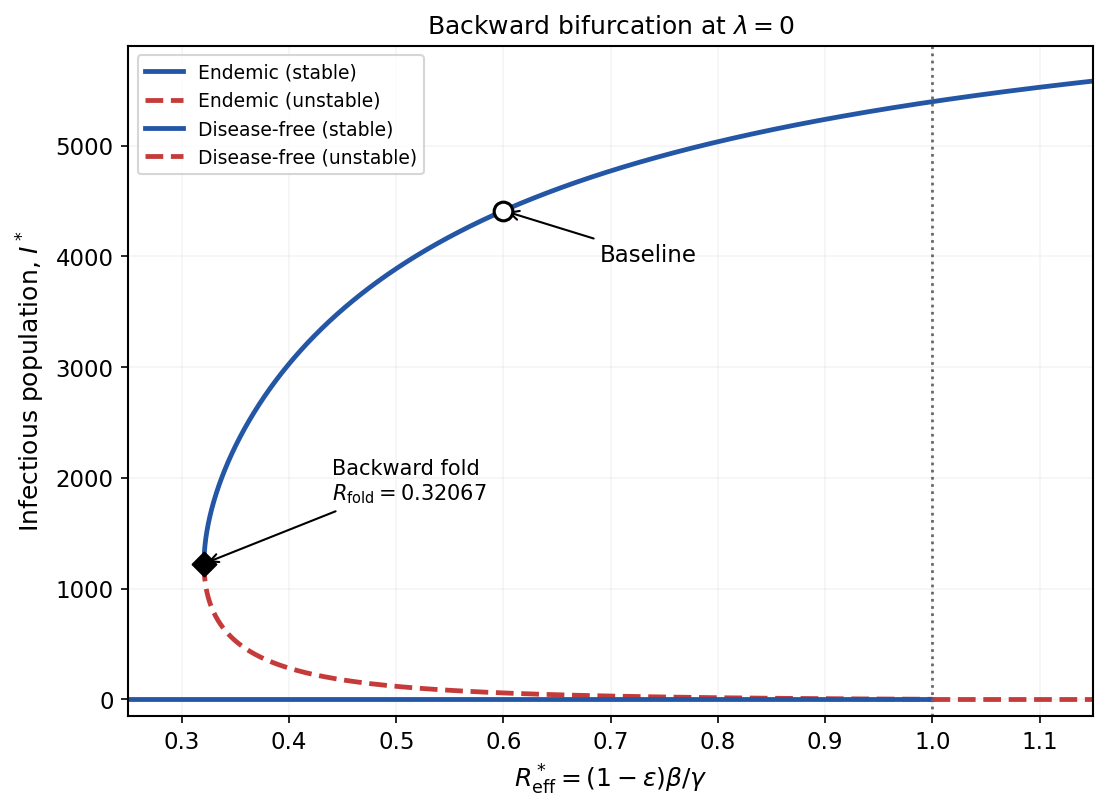

Backward fold:
beta = 0.3206686379
Reff = 0.3206686379
I* = 1225.058175
Discriminant = 2.776e-17


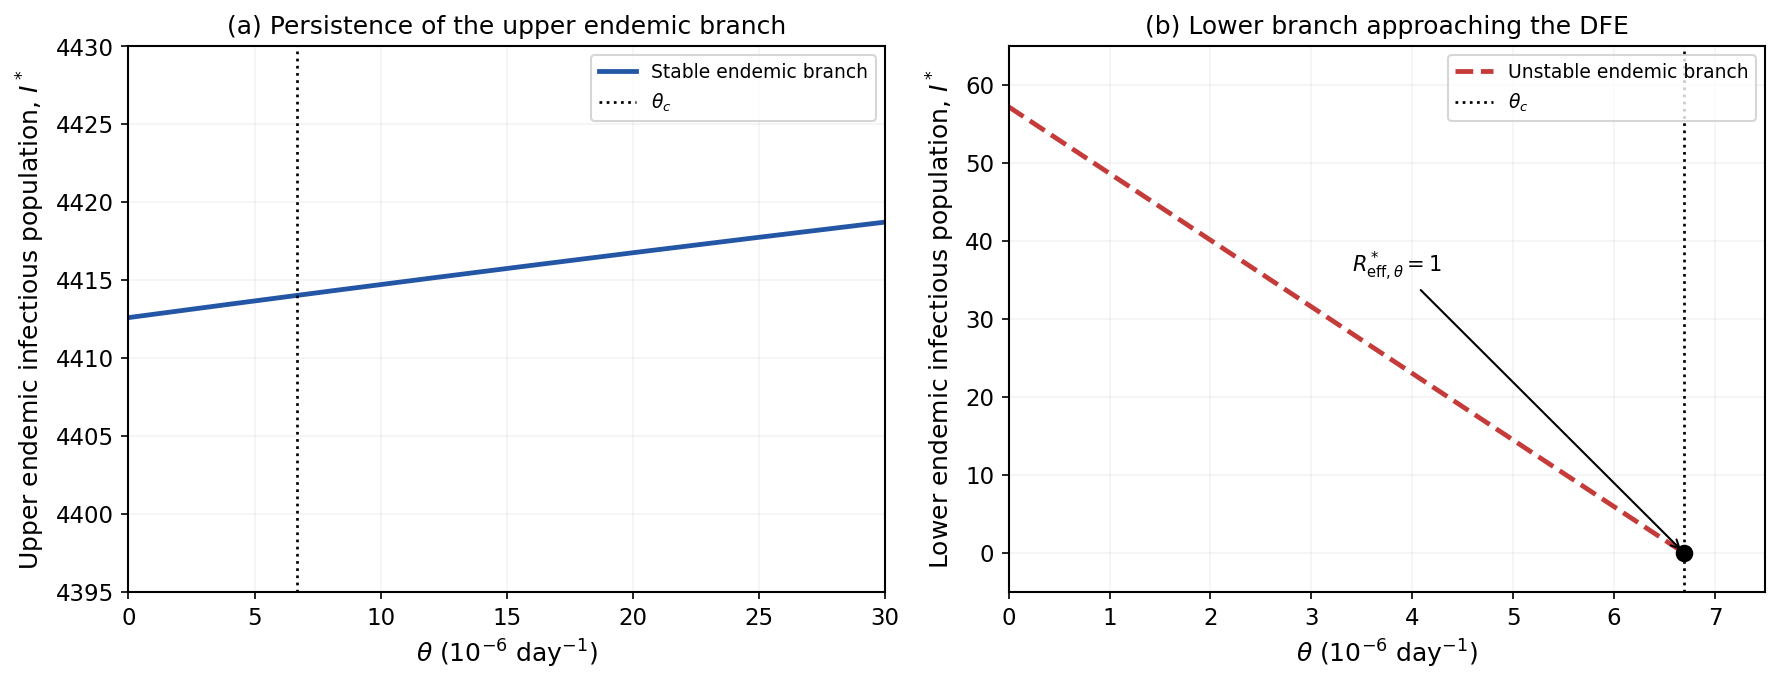


Critical vaccine-waning threshold:
theta_c = 6.6928509243e-06 day^-1
Duration = 409.3511 years


In [18]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from dataclasses import replace

# Uses your existing:
# base, x0, H, endemic_roots, classify, theta_critical, OUT

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "axes.linewidth": 1.0
})

BLUE = "#2456A6"
RED = "#C43B39"
GRAY = "#666666"

def save_publication_figure(fig, filename):
    fig.savefig(
        OUT / f"{filename}.png",
        dpi=400,
        bbox_inches="tight"
    )
    fig.savefig(
        OUT / f"{filename}.pdf",
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


# ============================================================
# FIGURE 1: BACKWARD BIFURCATION
# EXACT FOLD + DENSE SAMPLING NEAR FOLD
# ============================================================

x = x0(base)

def quadratic_coefficients(beta):
    q = replace(base, beta=float(beta))

    A = beta * H(x, q)
    B = q.phi * x * H(x, q) + q.gamma - beta
    C = q.phi * x * (
        q.gamma / ((1-q.epsilon)*beta) - 1
    )

    return A, B, C

def discriminant_beta(beta):
    A, B, C = quadratic_coefficients(beta)
    return B**2 - 4*A*C

# Bracket the physical backward fold
beta_fold = brentq(
    discriminant_beta,
    0.30,
    0.40,
    xtol=1e-14
)

A_f, B_f, C_f = quadratic_coefficients(beta_fold)

I_fold = base.N * (-B_f / (2*A_f))
R_fold = (
    (1-base.epsilon)*beta_fold/base.gamma
)

# Quadratically spaced grid: high resolution near fold
u = np.linspace(0, 1, 2500)
beta_grid = beta_fold + (1.15-beta_fold)*u**2

lower_I = []
upper_I = []
R_values = []

for beta in beta_grid:
    A, B, C = quadratic_coefficients(beta)
    delta = max(0.0, B**2 - 4*A*C)

    r1 = (-B - np.sqrt(delta))/(2*A)
    r2 = (-B + np.sqrt(delta))/(2*A)

    R_values.append(
        (1-base.epsilon)*beta/base.gamma
    )
    lower_I.append(base.N*r1)
    upper_I.append(base.N*r2)

R_values = np.asarray(R_values)
lower_I = np.asarray(lower_I)
upper_I = np.asarray(upper_I)

# Keep the physical positive lower branch
lower_I = np.where(
    lower_I >= -1e-8,
    np.maximum(lower_I, 0),
    np.nan
)

# Explicitly include the fold point
R_values[0] = R_fold
lower_I[0] = I_fold
upper_I[0] = I_fold

# Verify stability along the sampled branches
for beta in [0.35, 0.6, 0.9]:
    q = replace(base, beta=beta)
    roots = endemic_roots(q)

    if len(roots) == 2:
        labels = [classify(y, q)[0] for y in roots]
        assert labels == ["unstable", "stable"], (
            f"Unexpected stability at beta={beta}: {labels}"
        )

fig, ax = plt.subplots(figsize=(8.3, 5.8))

ax.plot(
    R_values, upper_I,
    color=BLUE, lw=2.3,
    label="Endemic (stable)"
)

ax.plot(
    R_values, lower_I,
    color=RED, lw=2.3, ls="--",
    label="Endemic (unstable)"
)

# Disease-free branch
ax.plot(
    [0.25, 1], [0, 0],
    color=BLUE, lw=2.3,
    label="Disease-free (stable)"
)

ax.plot(
    [1, 1.15], [0, 0],
    color=RED, lw=2.3, ls="--",
    label="Disease-free (unstable)"
)

ax.scatter(
    R_fold, I_fold,
    color="black", marker="D",
    s=65, zorder=8
)

ax.annotate(
    f"Backward fold\n"
    f"$R_{{\\mathrm{{fold}}}}={R_fold:.5f}$",
    xy=(R_fold, I_fold),
    xytext=(0.44, 1800),
    arrowprops=dict(arrowstyle="->", lw=1),
    fontsize=10
)

baseline_upper = max(
    y[3] for y in endemic_roots(base)
)

ax.scatter(
    0.6, baseline_upper,
    facecolor="white",
    edgecolor="black",
    s=80, lw=1.5, zorder=8
)

ax.annotate(
    "Baseline",
    xy=(0.6, baseline_upper),
    xytext=(0.69, 3950),
    arrowprops=dict(arrowstyle="->", lw=1)
)

ax.axvline(
    1, color=GRAY, ls=":", lw=1.3
)

ax.set_xlim(0.25, 1.15)
ax.set_ylim(-150, 5900)

ax.set_xlabel(
    r"$R_{\mathrm{eff}}^*=(1-\varepsilon)\beta/\gamma$"
)
ax.set_ylabel(r"Infectious population, $I^*$")
ax.set_title(
    r"Backward bifurcation at $\lambda=0$"
)

ax.legend(loc="upper left")
ax.grid(alpha=0.13)

save_publication_figure(
    fig, "fig1_backward_bifurcation_final"
)

print("Backward fold:")
print(f"beta = {beta_fold:.10f}")
print(f"Reff = {R_fold:.10f}")
print(f"I* = {I_fold:.6f}")
print(f"Discriminant = {discriminant_beta(beta_fold):.3e}")


# ============================================================
# FIGURE 2: DIRECT VACCINE-WANING SENSITIVITY
# HIGH-RESOLUTION NEAR THRESHOLD
# ============================================================

theta_c = theta_critical(base)

# Dense sampling below the threshold
theta_values = theta_c * (
    1 - (1-np.linspace(0, 1, 1400))**2
)

lower_theta = []
lower_branch = []
upper_theta = []
upper_branch = []

for theta in theta_values:

    q = replace(
        base,
        lam=0,
        theta=float(theta)
    )

    roots = endemic_roots(q)

    if len(roots) == 2:
        lower_theta.append(theta*1e6)
        lower_branch.append(roots[0][3])

        upper_theta.append(theta*1e6)
        upper_branch.append(roots[1][3])

# Include exact limiting point of lower branch
lower_theta.append(theta_c*1e6)
lower_branch.append(0.0)

# Higher branch beyond threshold
theta_extended = np.linspace(
    theta_c*1.0001,
    1/(365*10),
    400
)

for theta in theta_extended:
    q = replace(base, lam=0, theta=float(theta))
    roots = endemic_roots(q)

    if len(roots) == 1:
        upper_theta.append(theta*1e6)
        upper_branch.append(roots[0][3])

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.7)
)

# Panel A: upper endemic equilibrium
ax = axes[0]

ax.plot(
    upper_theta, upper_branch,
    color=BLUE, lw=2.3,
    label="Stable endemic branch"
)

ax.axvline(
    theta_c*1e6,
    color="black", ls=":", lw=1.3,
    label=r"$\theta_c$"
)

ax.set_xlim(0, 30)
ax.set_ylim(4395, 4430)

ax.set_xlabel(
    r"$\theta$ ($10^{-6}$ day$^{-1}$)"
)
ax.set_ylabel(
    r"Upper endemic infectious population, $I^*$"
)
ax.set_title("(a) Persistence of the upper endemic branch")
ax.legend()
ax.grid(alpha=0.15)

# Panel B: lower endemic branch
ax = axes[1]

ax.plot(
    lower_theta, lower_branch,
    color=RED, lw=2.3, ls="--",
    label="Unstable endemic branch"
)

ax.scatter(
    [theta_c*1e6], [0],
    color="black", s=55, zorder=7
)

ax.axvline(
    theta_c*1e6,
    color="black", ls=":", lw=1.3,
    label=r"$\theta_c$"
)

ax.annotate(
    r"$R_{\mathrm{eff},\theta}^*=1$",
    xy=(theta_c*1e6, 0),
    xytext=(3.4, 36),
    arrowprops=dict(arrowstyle="->", lw=1),
    fontsize=10
)

ax.set_xlim(0, 7.5)
ax.set_ylim(-5, 65)

ax.set_xlabel(
    r"$\theta$ ($10^{-6}$ day$^{-1}$)"
)
ax.set_ylabel(
    r"Lower endemic infectious population, $I^*$"
)
ax.set_title("(b) Lower branch approaching the DFE")
ax.legend(loc="upper right")
ax.grid(alpha=0.15)

plt.tight_layout()

save_publication_figure(
    fig, "fig2_vaccine_waning_final"
)

print("\nCritical vaccine-waning threshold:")
print(f"theta_c = {theta_c:.10e} day^-1")
print(f"Duration = {1/(365*theta_c):.4f} years")


PART A: FULL JACOBIAN STABILITY SCAN

Stability classification counts:
stability      stable  unstable
branch                         
DFE              2572       228
Lower endemic     228      2171
Upper endemic    2171         0

Maximum equilibrium residual:
6.412648190234904e-13

Maximum eigenvalue by branch:
                    min           max
branch                               
DFE           -0.000033  1.609127e-02
Lower endemic -0.001291  6.151150e-04
Upper endemic -0.001085 -2.748063e-07
Lower endemic: 228 unexpected classifications
Upper endemic: 0 unexpected classifications
Unexpected DFE classifications: 0

PART B: FEEDBACK-DEPENDENT SADDLE-NODE
No waning    lambda_fold=31.1257273 I_fold=152.55004 residual=2.30e-19
1000 years   lambda_fold=37.6776609 I_fold=104.33606 residual=1.29e-15
500 years    lambda_fold=52.2515353 I_fold=47.13477 residual=8.82e-16
410 years    lambda_fold=83.1935281 I_fold=3.26656 residual=1.32e-15

Branch counts:
scenario    stability
10 years    

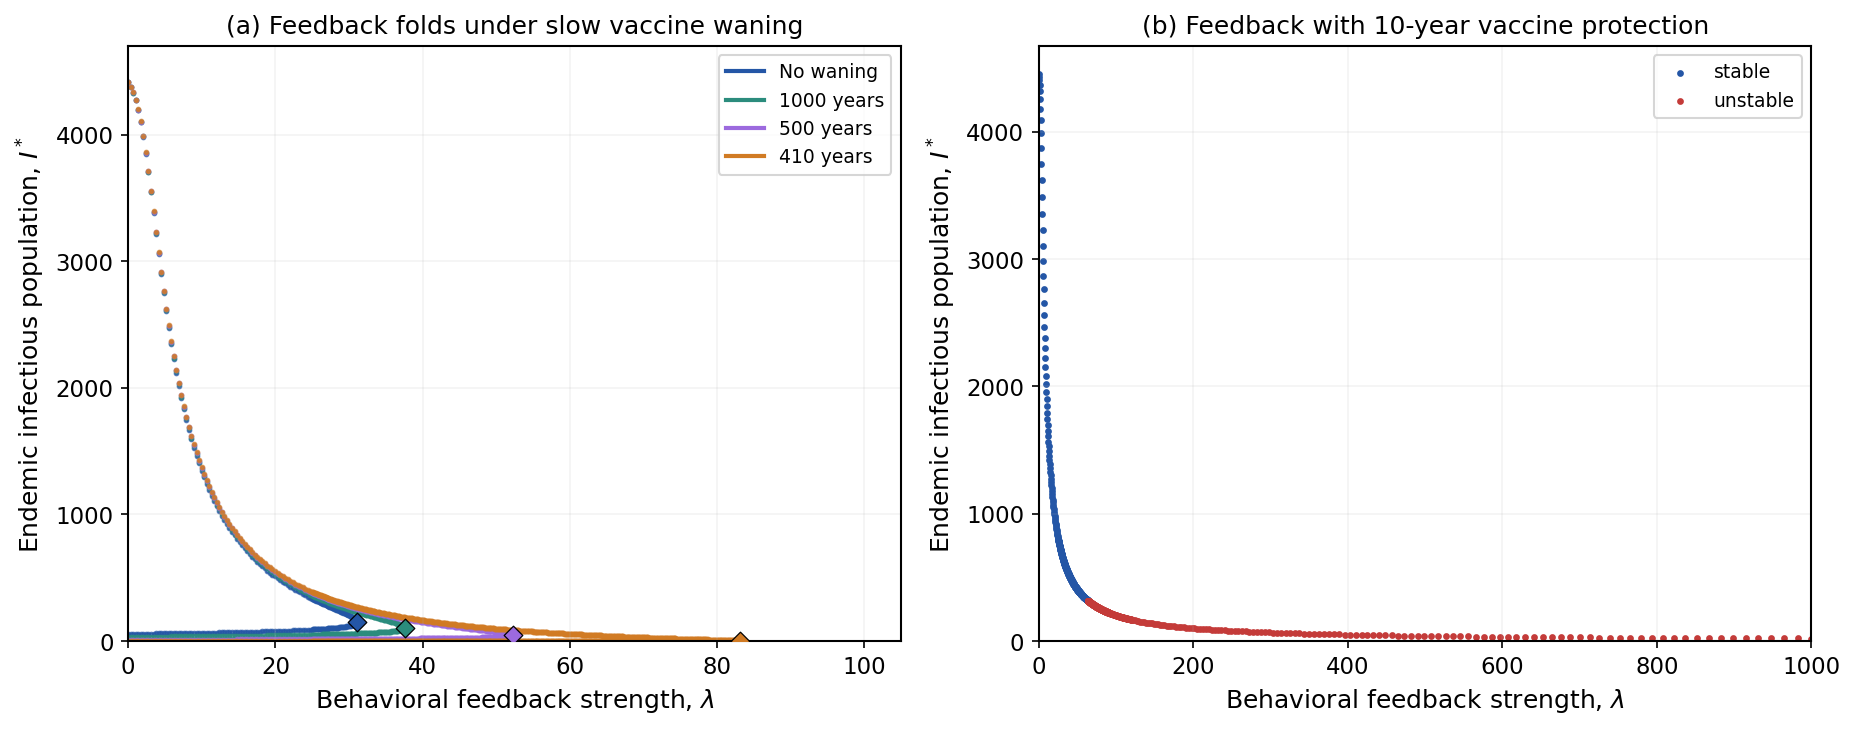


Analysis completed.
All CSV files and figures saved to: results


In [19]:

# ============================================================
# COMPLETE STABILITY SCAN + FEEDBACK SADDLE-NODE CONTINUATION
# Run after the original model-definition cell
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import replace
from scipy.optimize import root, brentq

# ============================================================
# PART A: COMPLETE STABILITY SCAN FOR FIGURE 1
# ============================================================

print("=" * 65)
print("PART A: FULL JACOBIAN STABILITY SCAN")
print("=" * 65)

# Previously calculated backward fold
beta_fold = 0.3206686379

# Dense sampling near fold
u = np.linspace(1e-6, 1, 2400)

beta_values = (
    beta_fold + (1.15 - beta_fold) * u**2
)

records = []

for beta in beta_values:

    q = replace(
        base,
        beta=float(beta),
        lam=0,
        theta=0
    )

    # Disease-free equilibrium
    y_dfe = dfe(q)
    dfe_status, dfe_eig = classify(y_dfe, q)

    records.append({
        "beta": beta,
        "R_eff": Reff(q),
        "branch": "DFE",
        "I_star": 0.0,
        "stability": dfe_status,
        "max_real_eigenvalue": dfe_eig,
        "residual": np.max(
            np.abs(rhs(0, y_dfe, q))
        )
    })

    # Both endemic equilibria
    equilibria = endemic_roots(q)

    for j, y in enumerate(equilibria):

        status, maxeig = classify(y, q)

        records.append({
            "beta": beta,
            "R_eff": Reff(q),
            "branch": (
                "Lower endemic"
                if j == 0
                else "Upper endemic"
            ),
            "I_star": y[3],
            "stability": status,
            "max_real_eigenvalue": maxeig,
            "residual": np.max(
                np.abs(rhs(0, y, q))
            )
        })

# DFE also needs scanning below the fold
for beta in np.linspace(0.20, beta_fold, 400):

    q = replace(
        base,
        beta=float(beta),
        lam=0,
        theta=0
    )

    y = dfe(q)
    status, eig = classify(y, q)

    records.append({
        "beta": beta,
        "R_eff": Reff(q),
        "branch": "DFE",
        "I_star": 0.0,
        "stability": status,
        "max_real_eigenvalue": eig,
        "residual": np.max(
            np.abs(rhs(0, y, q))
        )
    })

stability_df = pd.DataFrame(records)

stability_df.to_csv(
    OUT / "full_stability_scan_fig1.csv",
    index=False
)

print("\nStability classification counts:")
print(pd.crosstab(
    stability_df["branch"],
    stability_df["stability"]
))

print("\nMaximum equilibrium residual:")
print(stability_df["residual"].max())

print("\nMaximum eigenvalue by branch:")
print(
    stability_df.groupby("branch")[
        "max_real_eigenvalue"
    ].agg(["min", "max"])
)

# Flag unexpected stability classifications
expected = {
    "Lower endemic": "unstable",
    "Upper endemic": "stable"
}

for branch, expected_status in expected.items():

    subset = stability_df[
        stability_df.branch == branch
    ]

    unexpected = subset[
        subset.stability != expected_status
    ]

    print(
        f"{branch}: "
        f"{len(unexpected)} unexpected classifications"
    )

# Verify DFE stability away from R_eff = 1
dfe_rows = stability_df[
    stability_df.branch == "DFE"
]

bad_dfe = dfe_rows[
    (
        (dfe_rows.R_eff < 1 - 1e-6)
        & (dfe_rows.stability != "stable")
    )
    |
    (
        (dfe_rows.R_eff > 1 + 1e-6)
        & (dfe_rows.stability != "unstable")
    )
]

print(
    "Unexpected DFE classifications:",
    len(bad_dfe)
)

# ============================================================
# PART B: GENERAL ENDEMIC EQUILIBRIUM WITH FEEDBACK
# ============================================================

print("\n" + "=" * 65)
print("PART B: FEEDBACK-DEPENDENT SADDLE-NODE")
print("=" * 65)

# i = I/N
# At equilibrium T = lambda*i/mu
# Hence x depends on both i and lambda.

def feedback_x(i, lam, q):

    Tstar = lam * i / q.mu

    return sigmoid(Tstar, q)


def equilibrium_F(i, lam, q):

    x = feedback_x(i, lam, q)

    # No direct waning:
    # use the original quadratic equilibrium equation.
    if q.theta == 0:

        A = q.beta * H(x, q)

        B = (
            q.phi*x*H(x, q)
            + q.gamma
            - q.beta
        )

        C = q.phi*x*(
            q.gamma /
            ((1-q.epsilon)*q.beta)
            - 1
        )

        return A*i*i + B*i + C

    # Direct vaccine waning:
    # eliminate S, V, E, RN, RV
    D = (
        q.theta
        + (1-q.epsilon)*q.beta*i
    )

    Sfrac = (
        q.gamma /
        (
            q.beta * (
                1
                + (1-q.epsilon)*q.phi*x/D
            )
        )
    )

    Vfrac = q.phi*x*Sfrac/D

    return (
        Sfrac
        + Vfrac
        + H(x, q)*i
        - 1
    )


def equilibrium_dFdi(i, lam, q):

    # Complex-step derivative
    h = 1e-25

    return np.imag(
        equilibrium_F(i + 1j*h, lam, q)
    ) / h


def equilibrium_state(i, lam, q):

    x = feedback_x(i, lam, q)

    D = (
        q.theta
        + (1-q.epsilon)*q.beta*i
    )

    Sfrac = (
        q.gamma /
        (
            q.beta * (
                1
                + (1-q.epsilon)*q.phi*x/D
            )
        )
    )

    Vfrac = q.phi*x*Sfrac/D

    Efrac = q.gamma/q.sigma*i

    RNfrac = (
        (1-x)*q.gamma/q.omegaN*i
    )

    RVfrac = (
        x*q.gamma/q.omegaV*i
    )

    Tstar = lam*i/q.mu

    return np.array([
        q.N*Sfrac,
        q.N*Vfrac,
        q.N*Efrac,
        q.N*i,
        q.N*RNfrac,
        q.N*RVfrac,
        Tstar
    ])


def find_feedback_roots(lam, q):

    # Logarithmic sampling captures very small roots.
    # Linear sampling captures the upper endemic branch.
    grid = np.unique(np.r_[
        np.geomspace(1e-12, 0.1, 1400),
        np.linspace(1e-7, 0.1, 1400)
    ])

    fvals = np.array([
        equilibrium_F(i, lam, q)
        for i in grid
    ])

    roots_found = []

    for j in range(len(grid)-1):

        fa = fvals[j]
        fb = fvals[j+1]

        if (
            np.isfinite(fa)
            and np.isfinite(fb)
            and fa*fb < 0
        ):

            r = brentq(
                lambda i: equilibrium_F(i, lam, q),
                grid[j],
                grid[j+1],
                xtol=1e-15
            )

            if (
                not roots_found
                or abs(r-roots_found[-1]) > 1e-9
            ):
                roots_found.append(r)

    return roots_found


def solve_feedback_fold(q, guess):

    # Fold equations:
    # F(i,lambda) = 0
    # dF/di = 0

    def equations(z):

        i, lam = z

        return np.array([
            equilibrium_F(i, lam, q),
            0.001*equilibrium_dFdi(i, lam, q)
        ])

    sol = root(
        equations,
        guess,
        method="hybr",
        tol=1e-11
    )

    i, lam = sol.x

    residual = np.max(
        np.abs(equations(sol.x))
    )

    valid = (
        i > 0
        and lam >= 0
        and residual < 1e-8
    )

    return {
        "converged": bool(valid),
        "I_fold": q.N*i if valid else np.nan,
        "lambda_fold": lam if valid else np.nan,
        "residual": residual,
        "i": i,
        "lambda": lam
    }


# ============================================================
# PART C: FOLD COMPUTATIONS FOR DIFFERENT WANING RATES
# ============================================================

scenarios = [
    ("No waning", np.inf, (0.00015255, 31.1257)),
    ("1000 years", 1000, (0.000104, 37.68)),
    ("500 years", 500, (0.000047, 52.25)),
    ("410 years", 410, (0.00000327, 83.19)),
    ("400 years", 400, None),
    ("100 years", 100, None),
    ("10 years", 10, None)
]

fold_records = []

for name, years, guess in scenarios:

    theta = (
        0 if np.isinf(years)
        else 1/(365*years)
    )

    q = replace(
        base,
        beta=0.6,
        theta=theta
    )

    if guess is not None:

        result = solve_feedback_fold(q, guess)

        fold_records.append({
            "scenario": name,
            "theta": theta,
            "R_eff_DFE": Reff(q),
            **result
        })

        print(
            f"{name:12s} "
            f"lambda_fold={result['lambda_fold']:.7f} "
            f"I_fold={result['I_fold']:.5f} "
            f"residual={result['residual']:.2e}"
        )

    else:
        fold_records.append({
            "scenario": name,
            "theta": theta,
            "R_eff_DFE": Reff(q),
            "converged": False,
            "I_fold": np.nan,
            "lambda_fold": np.nan,
            "residual": np.nan
        })

fold_df = pd.DataFrame(fold_records)

fold_df.to_csv(
    OUT / "feedback_fold_sensitivity.csv",
    index=False
)

# ============================================================
# PART D: FULL EQUILIBRIUM BRANCH SCAN AGAINST LAMBDA
# ============================================================

branch_records = []

# Dense near the original fold, broader elsewhere
lambda_values = np.unique(np.r_[
    np.linspace(0, 120, 350),
    np.linspace(25, 90, 500),
    np.geomspace(120, 1000, 120)
])

for name, years, guess in scenarios:

    theta = (
        0 if np.isinf(years)
        else 1/(365*years)
    )

    q = replace(
        base,
        theta=theta
    )

    for lam in lambda_values:

        roots_here = find_feedback_roots(
            float(lam), q
        )

        for i in roots_here:

            y = equilibrium_state(
                i, float(lam), q
            )

            status, maxeig = classify(y, q)

            residual = np.max(
                np.abs(rhs(0, y, q))
            )

            branch_records.append({
                "scenario": name,
                "theta": theta,
                "lambda": lam,
                "I_star": q.N*i,
                "stability": status,
                "max_real_eigenvalue": maxeig,
                "residual": residual
            })

feedback_df = pd.DataFrame(
    branch_records
)

feedback_df.to_csv(
    OUT / "feedback_equilibrium_branches.csv",
    index=False
)

print("\nBranch counts:")
print(
    feedback_df.groupby(
        ["scenario", "stability"]
    ).size()
)

print("\nMaximum full-model residual:")
print(feedback_df.residual.max())

# ============================================================
# PART E: FEEDBACK SADDLE-NODE FIGURE
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 5)
)

colors = {
    "No waning": "#2456A6",
    "1000 years": "#2B8C7D",
    "500 years": "#9C6ADE",
    "410 years": "#D17B24",
    "10 years": "#C43B39"
}

# Panel A: fold-producing scenarios
ax = axes[0]

for name in [
    "No waning",
    "1000 years",
    "500 years",
    "410 years"
]:

    df = feedback_df[
        feedback_df.scenario == name
    ]

    for status, linestyle in [
        ("stable", "-"),
        ("unstable", "--")
    ]:

        part = df[
            df.stability == status
        ]

        ax.scatter(
            part["lambda"],
            part["I_star"],
            s=3,
            color=colors[name],
            alpha=0.75
        )

    # Mark computed fold
    row = fold_df[
        fold_df.scenario == name
    ].iloc[0]

    if row["converged"]:
        ax.scatter(
            row["lambda_fold"],
            row["I_fold"],
            marker="D",
            s=40,
            color=colors[name],
            edgecolor="black",
            linewidth=0.6,
            zorder=10
        )

    # Legend entry
    ax.plot(
        [], [],
        color=colors[name],
        lw=2,
        label=name
    )

ax.set_xlim(0, 105)
ax.set_ylim(0, 4700)

ax.set_xlabel(
    r"Behavioral feedback strength, $\lambda$"
)
ax.set_ylabel(
    r"Endemic infectious population, $I^*$"
)
ax.set_title("(a) Feedback folds under slow vaccine waning")
ax.legend(fontsize=9)
ax.grid(alpha=0.15)


# Panel B: 10-year protection scenario
ax = axes[1]

df = feedback_df[
    feedback_df.scenario == "10 years"
]

for status, color, linestyle in [
    ("stable", "#2456A6", "-"),
    ("unstable", "#C43B39", "--")
]:

    part = df[
        df.stability == status
    ]

    ax.scatter(
        part["lambda"],
        part["I_star"],
        s=5,
        color=color,
        label=status
    )

ax.set_xlim(0, 1000)
ax.set_ylim(bottom=0)

ax.set_xlabel(
    r"Behavioral feedback strength, $\lambda$"
)
ax.set_ylabel(
    r"Endemic infectious population, $I^*$"
)
ax.set_title("(b) Feedback with 10-year vaccine protection")
ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()

plt.savefig(
    OUT / "feedback_fold_waning_comparison.png",
    dpi=400,
    bbox_inches="tight"
)

plt.savefig(
    OUT / "feedback_fold_waning_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nAnalysis completed.")
print("All CSV files and figures saved to:", OUT)


In [20]:

# ============================================================
# DIAGNOSTIC CORRECTIONS
# ============================================================

import numpy as np
import pandas as pd
from dataclasses import replace

# ------------------------------------------------------------
# A. Investigate unexpected lower-branch classifications
# ------------------------------------------------------------

lower = stability_df[
    stability_df["branch"] == "Lower endemic"
].copy()

print("LOWER ENDEMIC BRANCH DIAGNOSTICS")
print("=" * 60)

print("\nStability classifications by threshold region:")

lower["region"] = np.where(
    lower["R_eff"] < 1,
    "R_eff < 1",
    "R_eff >= 1"
)

print(
    pd.crosstab(
        lower["region"],
        lower["stability"]
    )
)

print("\nStable lower-branch records:")
print(
    lower[
        lower["stability"] == "stable"
    ][
        [
            "R_eff",
            "I_star",
            "max_real_eigenvalue"
        ]
    ].describe()
)

# Biologically admissible positive endemic equilibria
physical_lower = lower[
    (lower["R_eff"] < 1 - 1e-8)
    & (lower["I_star"] > 1e-6)
]

print("\nPhysical lower branch stability:")
print(
    physical_lower["stability"].value_counts()
)



# ============================================================
# CORRECTED FEEDBACK-DEPENDENT STABILITY SCAN
# Fixes the pandas "lambda" column error
# and uses the correct lambda in the Jacobian.
# ============================================================

import numpy as np
import pandas as pd
from dataclasses import replace

corrected_records = []

for _, row in feedback_df.iterrows():

    lam_value = float(row["lambda"])
    theta_value = float(row["theta"])
    i_value = float(row["I_star"]) / base.N

    # IMPORTANT:
    # Pass the actual lambda into the parameter object.
    q = replace(
        base,
        lam=lam_value,
        theta=theta_value
    )

    # Reconstruct equilibrium using this lambda
    y = equilibrium_state(
        i_value,
        lam_value,
        q
    )

    # Jacobian evaluated with correct lambda
    status, maxeig = classify(y, q)

    # Verify the full seven-state equilibrium residual
    residual = float(
        np.max(np.abs(rhs(0, y, q)))
    )

    corrected_records.append({
        "scenario": row["scenario"],
        "theta": theta_value,
        "lambda": lam_value,
        "I_star": float(y[3]),
        "stability": status,
        "max_real_eigenvalue": maxeig,
        "residual": residual
    })

feedback_corrected = pd.DataFrame(
    corrected_records
)

feedback_corrected.to_csv(
    OUT / "feedback_stability_corrected.csv",
    index=False
)

print("=" * 65)
print("CORRECTED FEEDBACK STABILITY RESULTS")
print("=" * 65)

print("\nStability classification counts:")
print(
    pd.crosstab(
        feedback_corrected["scenario"],
        feedback_corrected["stability"]
    )
)

print("\nEquilibrium residual statistics:")
print(
    feedback_corrected["residual"].describe()
)

print("\nMaximum residual:")
print(
    feedback_corrected["residual"].max()
)

bad = feedback_corrected[
    feedback_corrected["residual"] > 1e-5
]

print("\nNumber of records with residual > 1e-5:")
print(len(bad))

if len(bad) > 0:
    print("\nLargest residuals:")
    print(
        bad.nlargest(10, "residual")[
            [
                "scenario",
                "lambda",
                "I_star",
                "stability",
                "residual"
            ]
        ].to_string(index=False)
    )

print("\nCompleted.")


LOWER ENDEMIC BRANCH DIAGNOSTICS

Stability classifications by threshold region:
stability   stable  unstable
region                      
R_eff < 1        0      2171
R_eff >= 1     228         0

Stable lower-branch records:
            R_eff       I_star  max_real_eigenvalue
count  228.000000   228.000000           228.000000
mean     1.074007  5493.480028            -0.001186
std      0.043452    53.849879             0.000060
min      1.000478  5397.892804            -0.001291
25%      1.036466  5447.567954            -0.001237
50%      1.073383  5494.946690            -0.001185
75%      1.111227  5540.145163            -0.001135
max      1.150000  5583.274463            -0.001085

Physical lower branch stability:
stability
unstable    2171
Name: count, dtype: int64
CORRECTED FEEDBACK STABILITY RESULTS

Stability classification counts:
stability   stable  unstable
scenario                    
10 years        21       948
100 years      969         0
1000 years     208       208
40

Maximum equilibrium residual:
2.5579538487363607e-13

First 15 records:
   lambda      I_star  max_real  dominant_imag     residual
 0.000000 4451.214109 -0.000811       0.000000 2.065015e-13
 0.834028 4387.492049 -0.000815       0.000000 1.065814e-13
 1.668057 4266.093696 -0.000830       0.000000 1.527667e-13
 2.502085 4063.916135 -0.000867       0.000000 1.136868e-13
 3.336113 3786.125604 -0.000925       0.000000 2.557954e-13
 4.170142 3470.812019 -0.000744       0.017399 1.136868e-13
 5.004170 3158.445025 -0.000461       0.017435 1.847411e-13
 5.838198 2871.735878 -0.000235       0.017385 5.684342e-14
 6.672227 2618.038985 -0.000061       0.017274 1.705303e-13
 7.506255 2396.898437  0.000072       0.017127 1.278977e-13
 8.340284 2204.919303  0.000176       0.016963 5.684342e-14
 9.174312 2038.034040  0.000258       0.016795 5.684342e-14
10.008340 1892.392119  0.000324       0.016628 5.684342e-14
10.842369 1764.641513  0.000377       0.016467 5.684342e-14
11.676397 1651.965895  0.000

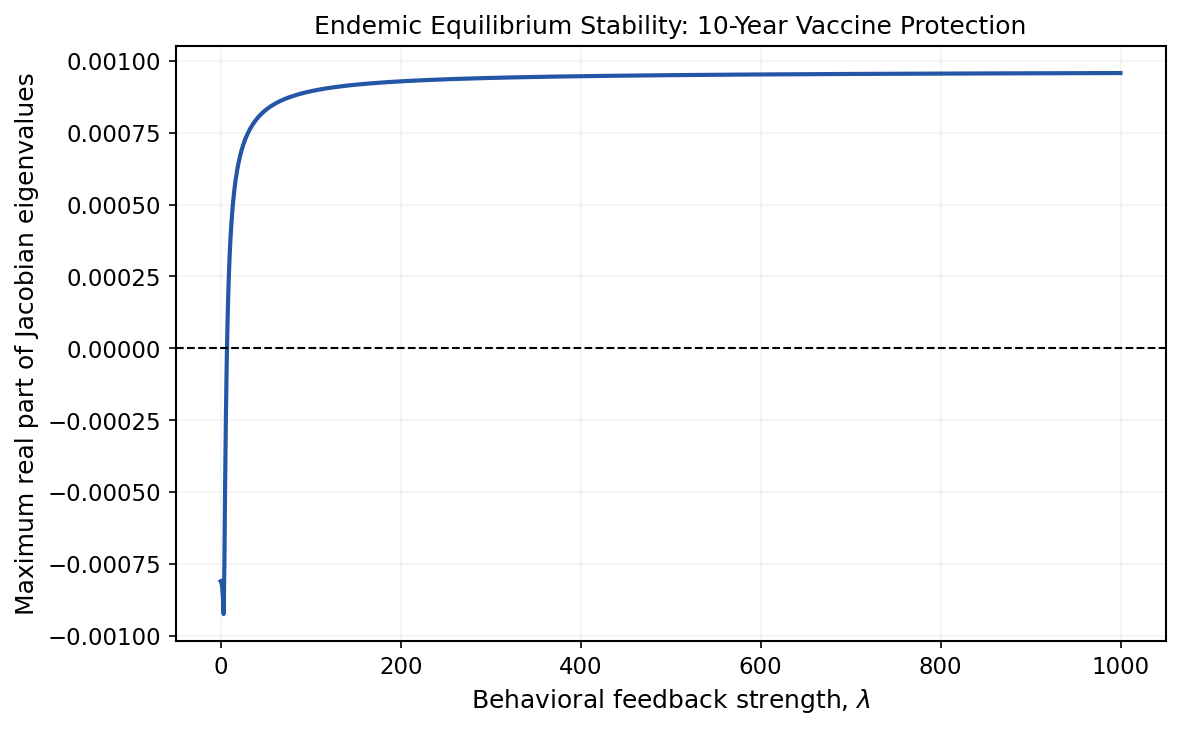

In [21]:

# ============================================================
# CHECK STABILITY TRANSITION FOR 10-YEAR PROTECTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace

theta10 = 1 / (365 * 10)

q10 = replace(
    base,
    theta=theta10
)

lambda_scan = np.linspace(0, 1000, 1200)

records = []

for lam in lambda_scan:

    q = replace(q10, lam=float(lam))

    roots = find_feedback_roots(
        float(lam), q
    )

    for i in roots:

        y = equilibrium_state(
            i, float(lam), q
        )

        J = jacobian(
            reduced_rhs, y[1:], q
        )

        eig = np.linalg.eigvals(J)

        dominant = eig[
            np.argmax(eig.real)
        ]

        records.append({
            "lambda": lam,
            "I_star": y[3],
            "max_real": dominant.real,
            "dominant_imag": dominant.imag,
            "residual": np.max(
                np.abs(rhs(0, y, q))
            )
        })

hopf_df = pd.DataFrame(records)

hopf_df.to_csv(
    OUT / "ten_year_eigenvalue_scan.csv",
    index=False
)

print("Maximum equilibrium residual:")
print(hopf_df.residual.max())

print("\nFirst 15 records:")
print(hopf_df.head(15).to_string(index=False))

# Detect real-part sign changes
values = hopf_df.max_real.to_numpy()
lambdas = hopf_df["lambda"].to_numpy()

crossings = np.where(
    values[:-1] * values[1:] < 0
)[0]

print("\nDetected stability crossings:")

for j in crossings:

    print(
        f"Between lambda={lambdas[j]:.6f} "
        f"and lambda={lambdas[j+1]:.6f}"
    )

    print(
        "Dominant imaginary parts:",
        hopf_df.dominant_imag.iloc[j],
        hopf_df.dominant_imag.iloc[j+1]
    )

# Plot dominant eigenvalue real part
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    hopf_df["lambda"],
    hopf_df["max_real"],
    color="#2456A6",
    lw=2
)

ax.axhline(
    0,
    color="black",
    ls="--",
    lw=1
)

ax.set_xlabel(
    r"Behavioral feedback strength, $\lambda$"
)

ax.set_ylabel(
    r"Maximum real part of Jacobian eigenvalues"
)

ax.set_title(
    "Endemic Equilibrium Stability: 10-Year Vaccine Protection"
)

ax.grid(alpha=0.15)

plt.tight_layout()

plt.savefig(
    OUT / "ten_year_stability_scan.png",
    dpi=400,
    bbox_inches="tight"
)

plt.savefig(
    OUT / "ten_year_stability_scan.pdf",
    bbox_inches="tight"
)

plt.show()


In [22]:

# ============================================================
# PRECISE HOPF POINT VERIFICATION
# 10-year mean vaccine-protection duration
# ============================================================

import numpy as np
from scipy.optimize import brentq
from dataclasses import replace

theta10 = 1 / (365 * 10)

def hopf_data(lam):
    q = replace(
        base,
        theta=theta10,
        lam=float(lam)
    )

    roots = find_feedback_roots(lam, q)

    if len(roots) != 1:
        raise RuntimeError(
            f"Expected one endemic root at lambda={lam}, "
            f"found {len(roots)}"
        )

    y = equilibrium_state(
        roots[0], lam, q
    )

    J = jacobian(reduced_rhs, y[1:], q)
    eig = np.linalg.eigvals(J)

    dominant = eig[np.argmax(eig.real)]

    residual = np.max(
        np.abs(rhs(0, y, q))
    )

    return dominant.real, dominant.imag, y, eig, residual


lambda_H = brentq(
    lambda lam: hopf_data(lam)[0],
    6.672227,
    7.506255,
    xtol=1e-12
)

real_H, imag_H, y_H, eig_H, residual_H = (
    hopf_data(lambda_H)
)

# Numerical transversality check
h = 1e-3

derivative = (
    hopf_data(lambda_H+h)[0]
    - hopf_data(lambda_H-h)[0]
) / (2*h)

print("=" * 60)
print("HOPF BIFURCATION VERIFICATION")
print("=" * 60)

print(f"lambda_H = {lambda_H:.12f}")
print(f"I_H = {y_H[3]:.8f}")
print(f"T_H = {y_H[6]:.8f}")

print("\nCritical eigenvalue:")
print(
    f"{real_H:.12e} "
    f"+ {abs(imag_H):.12f}i"
)

print("\nEigenvalue crossing derivative:")
print(f"d Re(eigenvalue)/d lambda = {derivative:.10e}")

print("\nAll reduced-Jacobian eigenvalues:")
for e in sorted(eig_H, key=lambda z: z.real, reverse=True):
    print(f"{e.real:+.12e} {e.imag:+.12e}i")

print("\nFull-model equilibrium residual:")
print(f"{residual_H:.12e}")

print("\nBasic Hopf conditions:")
print("Nonzero imaginary part:", abs(imag_H) > 1e-6)
print("Transverse crossing:", abs(derivative) > 1e-8)
print("Small real part:", abs(real_H) < 1e-8)


HOPF BIFURCATION VERIFICATION
lambda_H = 7.029126013138
I_H = 2519.58797387
T_H = 0.35421003

Critical eigenvalue:
1.301042606983e-17 + 0.017214163597i

Eigenvalue crossing derivative:
d Re(eigenvalue)/d lambda = 1.6262830402e-04

All reduced-Jacobian eigenvalues:
+1.301042606983e-17 +1.721416359687e-02i
+1.301042606983e-17 -1.721416359687e-02i
-1.206504923523e-03 +0.000000000000e+00i
-2.045171436920e-03 +0.000000000000e+00i
-5.363870446888e-02 +0.000000000000e+00i
-4.502512279899e-01 +0.000000000000e+00i

Full-model equilibrium residual:
1.421085471520e-13

Basic Hopf conditions:
Nonzero imaginary part: True
Transverse crossing: True
Small real part: True


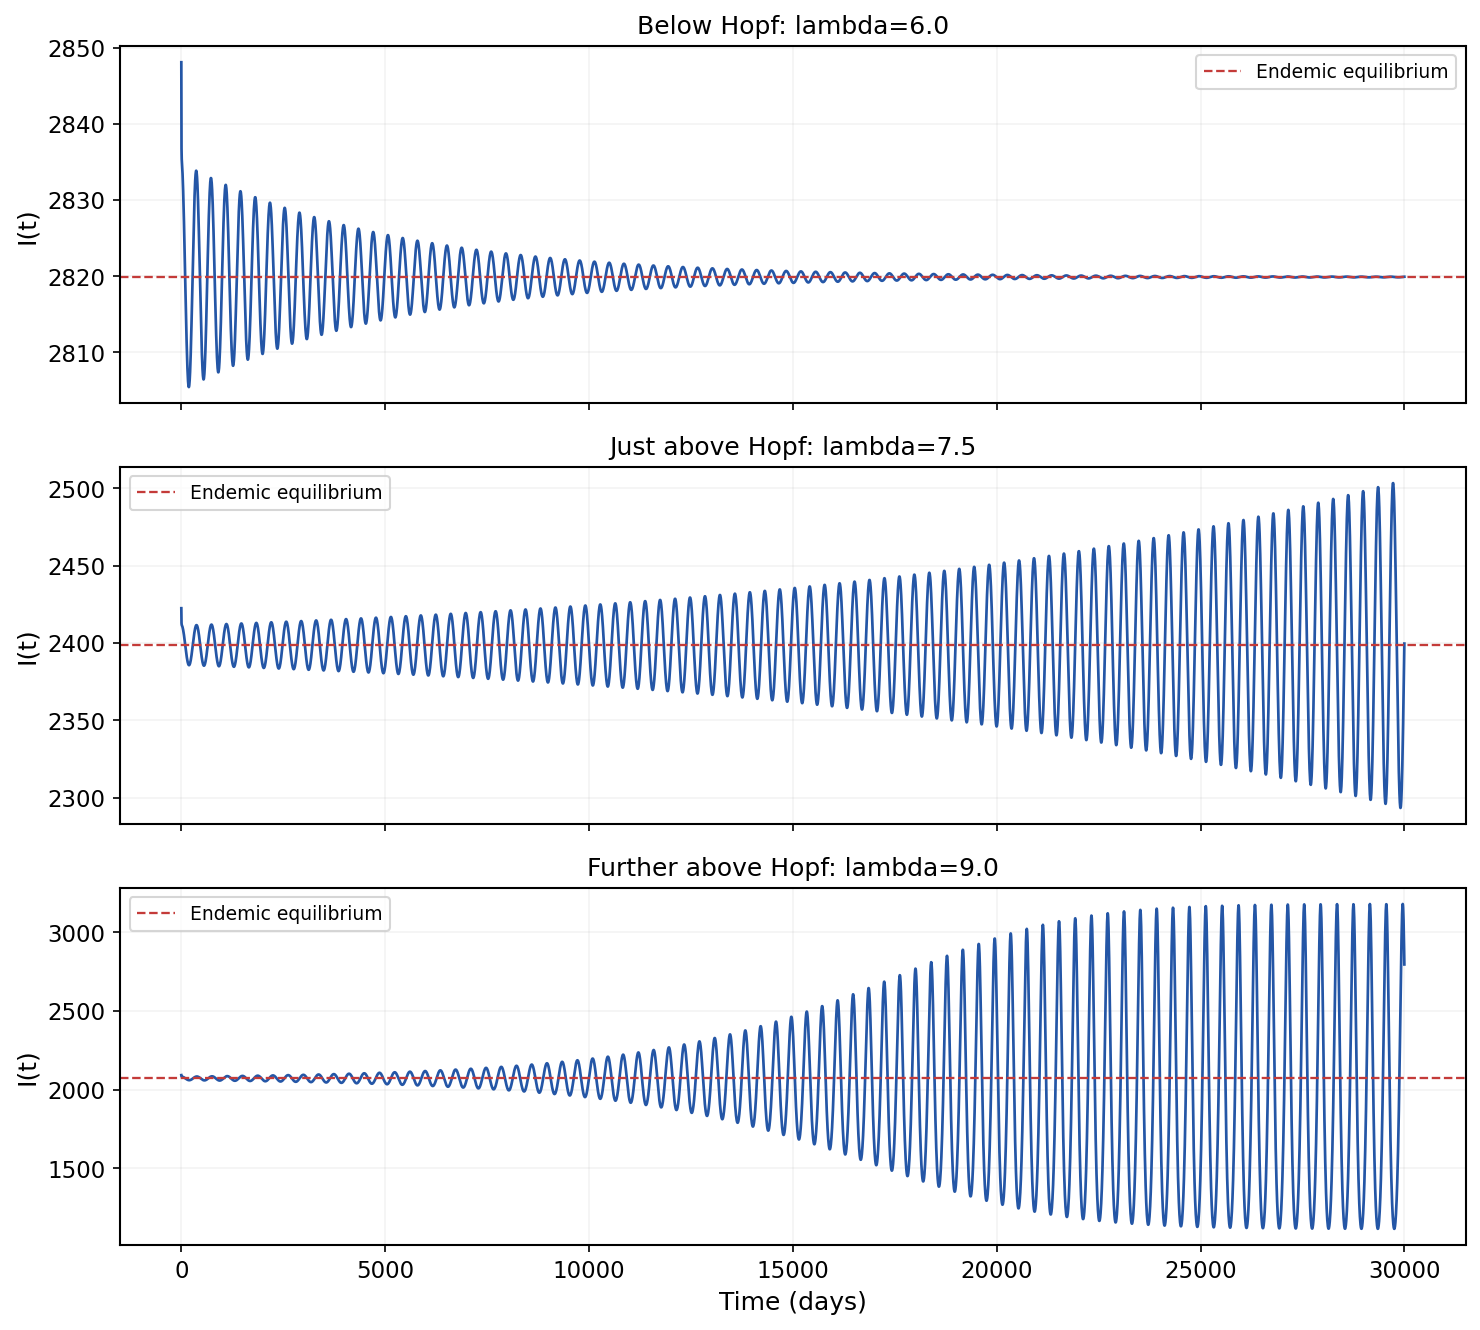


Late-time oscillation summary:
{'lambda': 6.0, 'equilibrium_I': np.float64(2819.881810419853), 'late_time_peak_to_peak': np.float64(0.5509401040385455), 'final_I': np.float64(2819.9152492294556)}
{'lambda': 7.5, 'equilibrium_I': np.float64(2398.443454006954), 'late_time_peak_to_peak': np.float64(210.0997492931674), 'final_I': np.float64(2399.551022312709)}
{'lambda': 9.0, 'equilibrium_I': np.float64(2071.0354808411535), 'late_time_peak_to_peak': np.float64(2061.4603422175433), 'final_I': np.float64(2794.0622068563994)}


In [23]:

# ============================================================
# TIME-DOMAIN VERIFICATION NEAR THE CANDIDATE HOPF POINT
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace
from scipy.integrate import solve_ivp

theta10 = 1 / (365 * 10)
lambda_H = 7.029126013138

scenarios = [
    (6.0, "Below Hopf"),
    (7.5, "Just above Hopf"),
    (9.0, "Further above Hopf")
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 9),
    sharex=True
)

summary = []

for ax, (lam, label) in zip(axes, scenarios):

    q = replace(
        base,
        theta=theta10,
        lam=lam
    )

    roots = find_feedback_roots(lam, q)

    if len(roots) != 1:
        raise RuntimeError(
            f"Expected one endemic root at lambda={lam}"
        )

    equilibrium = equilibrium_state(
        roots[0], lam, q
    )

    # Small perturbation around the endemic equilibrium
    y0 = equilibrium.copy()

    # Increase I by 1% and compensate in S
    perturbation = 0.01 * equilibrium[3]

    y0[3] += perturbation
    y0[0] -= perturbation

    sol = solve_ivp(
        lambda t, y: rhs(t, y, q),
        (0, 30000),
        y0,
        method="BDF",
        rtol=1e-9,
        atol=[1e-5]*6 + [1e-11],
        max_step=10,
        t_eval=np.linspace(0, 30000, 6000)
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    ax.plot(
        sol.t,
        sol.y[3],
        color="#2456A6",
        linewidth=1.3
    )

    ax.axhline(
        equilibrium[3],
        color="#C43B39",
        linestyle="--",
        linewidth=1.1,
        label="Endemic equilibrium"
    )

    ax.set_ylabel("I(t)")
    ax.set_title(
        f"{label}: lambda={lam}"
    )
    ax.legend()
    ax.grid(alpha=0.15)

    # Measure late-time oscillation amplitude
    tail = sol.y[3, sol.t >= 20000]

    amplitude = (
        np.max(tail) - np.min(tail)
    )

    summary.append({
        "lambda": lam,
        "equilibrium_I": equilibrium[3],
        "late_time_peak_to_peak": amplitude,
        "final_I": sol.y[3, -1]
    })

axes[-1].set_xlabel("Time (days)")

plt.tight_layout()

plt.savefig(
    OUT / "hopf_time_domain_comparison.png",
    dpi=400,
    bbox_inches="tight"
)

plt.savefig(
    OUT / "hopf_time_domain_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nLate-time oscillation summary:")
for item in summary:
    print(item)


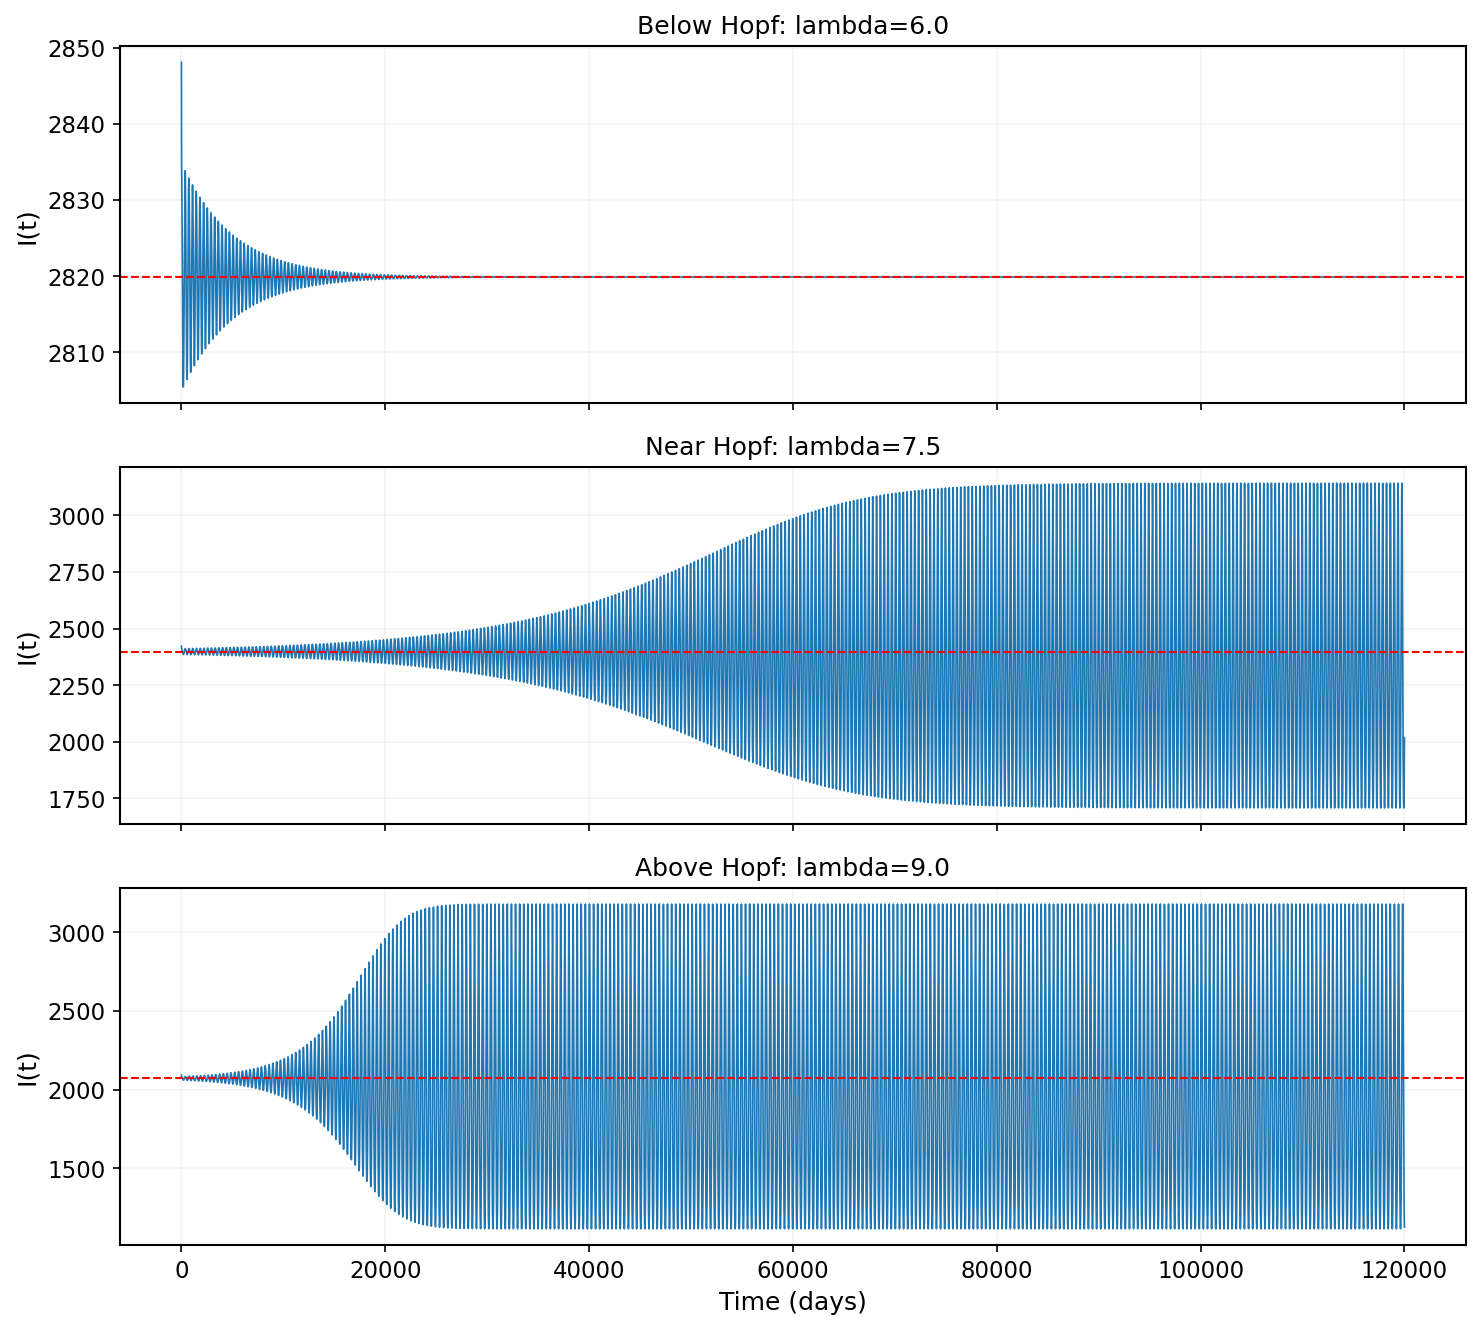

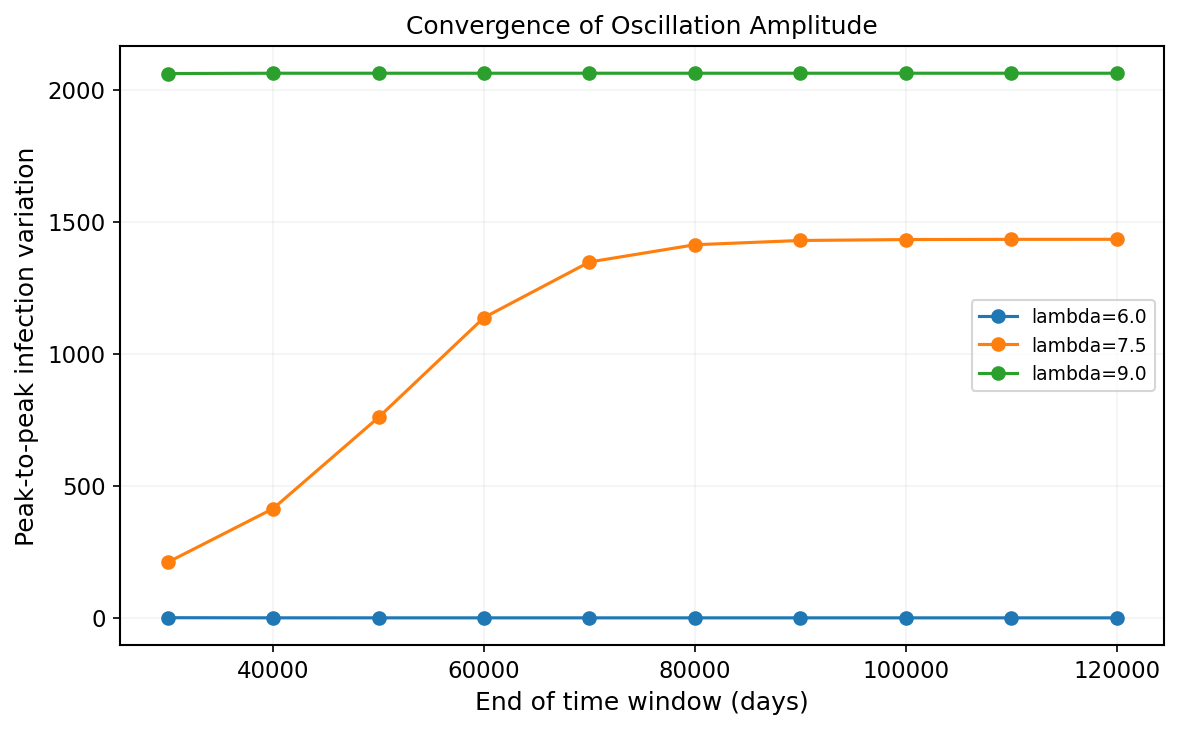


FINAL THREE WINDOWS:
 lambda  window_start  window_end  peak_to_peak  mean_period_days
    6.0         90000      100000  4.547474e-13               NaN
    6.0        100000      110000  4.547474e-13               NaN
    6.0        110000      120000  4.547474e-13               NaN
    7.5         90000      100000  1.432644e+03        376.538462
    7.5        100000      110000  1.433493e+03        376.346154
    7.5        110000      120000  1.433671e+03        376.400000
    9.0         90000      100000  2.062627e+03        402.826087
    9.0        100000      110000  2.062629e+03        402.916667
    9.0        110000      120000  2.062629e+03        402.916667


In [24]:

# ============================================================
# NONLINEAR OSCILLATION VERIFICATION
# Long-time convergence of epidemic oscillations
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from dataclasses import replace

theta10 = 1 / (365 * 10)

scenarios = [
    (6.0, "Below Hopf"),
    (7.5, "Near Hopf"),
    (9.0, "Above Hopf")
]

T_END = 120000
WINDOW = 10000

records = []

fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 9),
    sharex=True
)

for ax, (lam, label) in zip(axes, scenarios):

    q = replace(
        base,
        theta=theta10,
        lam=lam
    )

    roots = find_feedback_roots(lam, q)

    equilibrium = equilibrium_state(
        roots[0], lam, q
    )

    y0 = equilibrium.copy()

    perturbation = 0.01 * equilibrium[3]

    y0[3] += perturbation
    y0[0] -= perturbation

    sol = solve_ivp(
        lambda t, y: rhs(t, y, q),
        (0, T_END),
        y0,
        method="BDF",
        rtol=1e-9,
        atol=[1e-5]*6 + [1e-11],
        max_step=15,
        t_eval=np.arange(0, T_END+1, 5)
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    times = sol.t
    infections = sol.y[3]

    for start in np.arange(
        20000,
        T_END,
        WINDOW
    ):

        mask = (
            (times >= start)
            & (times < start+WINDOW)
        )

        t_window = times[mask]
        i_window = infections[mask]

        amplitude = (
            np.max(i_window)
            - np.min(i_window)
        )

        peaks, _ = find_peaks(
            i_window,
            prominence=1
        )

        if len(peaks) >= 2:
            mean_period = np.mean(
                np.diff(t_window[peaks])
            )
        else:
            mean_period = np.nan

        records.append({
            "lambda": lam,
            "window_start": start,
            "window_end": start+WINDOW,
            "peak_to_peak": amplitude,
            "mean_period_days": mean_period
        })

    ax.plot(
        times,
        infections,
        linewidth=0.8
    )

    ax.axhline(
        equilibrium[3],
        color="red",
        linestyle="--",
        linewidth=1
    )

    ax.set_ylabel("I(t)")
    ax.set_title(
        f"{label}: lambda={lam}"
    )

    ax.grid(alpha=0.15)

axes[-1].set_xlabel("Time (days)")

plt.tight_layout()

plt.savefig(
    OUT / "long_time_oscillations.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

amplitude_df = pd.DataFrame(records)

amplitude_df.to_csv(
    OUT / "oscillation_convergence.csv",
    index=False
)

# Plot amplitude convergence
fig, ax = plt.subplots(figsize=(8, 5))

for lam in [6.0, 7.5, 9.0]:

    part = amplitude_df[
        amplitude_df["lambda"] == lam
    ]

    ax.plot(
        part["window_end"],
        part["peak_to_peak"],
        marker="o",
        label=f"lambda={lam}"
    )

ax.set_xlabel("End of time window (days)")
ax.set_ylabel("Peak-to-peak infection variation")
ax.set_title("Convergence of Oscillation Amplitude")
ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()

plt.savefig(
    OUT / "oscillation_amplitude_convergence.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

print("\nFINAL THREE WINDOWS:")
print(
    amplitude_df.groupby("lambda")
    .tail(3)
    .to_string(index=False)
)


Equilibria:
DFE I* = 0.00000000
Lower endemic I* = 57.53811572
Upper endemic I* = 4358.37985564

CONVERGENCE DIAGNOSTICS
                                  scenario      final_I    target_I  population_error  trust_error  final_rhs_residual
                Baseline initial condition 4.358380e+03 4358.379856      9.313226e-09 5.828671e-16        1.250555e-12
Predominantly vaccinated initial condition 2.837665e-21    0.000000      4.612618e+00 1.567078e-26        1.543578e-04

POPULATION CONSERVATION
Baseline: 9.197e-09
Predominantly vaccinated: 4.191e-09


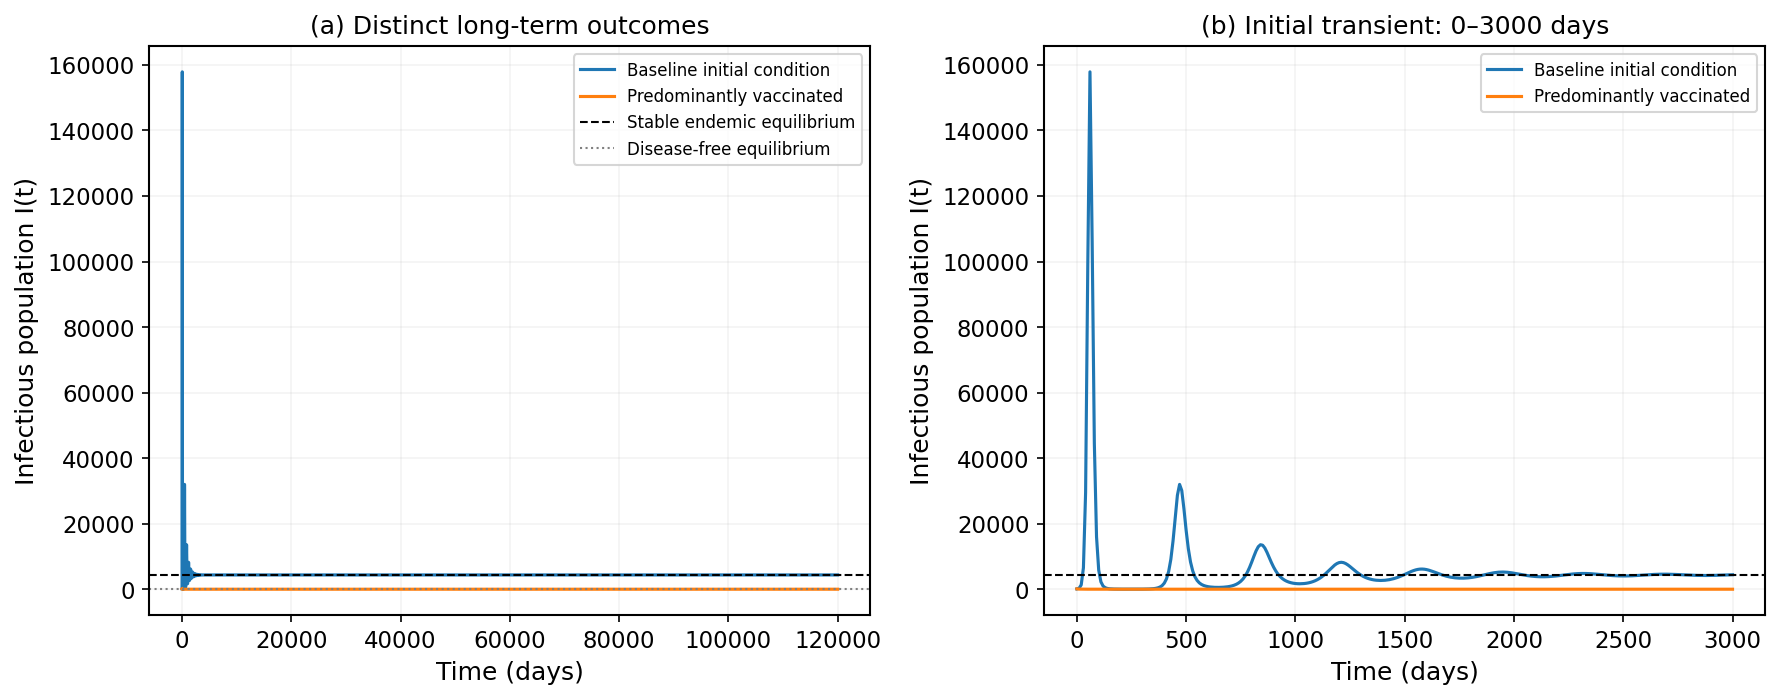

In [25]:

# ============================================================
# MAJOR COMMENT 2:
# TRAJECTORY-BASED VERIFICATION OF BISTABILITY
# Original model: theta = 0, lambda = 0.5
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import replace
from pathlib import Path
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# ------------------------------------------------------------
# 1. Baseline parameters
# ------------------------------------------------------------

q = replace(
    Params(),
    lam=0.5,
    theta=0.0
)

N = q.N

OUT = Path("bistability_verification")
OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Two initial conditions
# ------------------------------------------------------------

# Initial condition A:
# Baseline scenario, with initial trust-related state T=0.5
# This uses S=N-100, I=100, all other classes initially zero.
#
# IMPORTANT: Confirm that these are the exact values in
# Table IV of your manuscript before describing this
# as the Table IV initial condition.

y0_A = np.array([
    N - 100,   # S
    0,         # V
    0,         # E
    100,       # I
    0,         # RN
    0,         # RV
    0.5        # T
], dtype=float)

# Initial condition B:
# Reviewer's predominantly vaccinated initial condition
y0_B = np.array([
    0,         # S
    N - 100,   # V
    0,         # E
    100,       # I
    0,         # RN
    0,         # RV
    0.5        # T
], dtype=float)

# ------------------------------------------------------------
# 3. Compute the endemic equilibria numerically
# ------------------------------------------------------------

roots = find_feedback_roots(q.lam, q)

if len(roots) != 2:
    raise RuntimeError(
        f"Expected two endemic equilibria, found {len(roots)}"
    )

roots = sorted(roots)

eq_lower = equilibrium_state(roots[0], q.lam, q)
eq_upper = equilibrium_state(roots[1], q.lam, q)

# Disease-free equilibrium
eq_DFE = np.array([
    0,
    N,
    0,
    0,
    0,
    0,
    0
], dtype=float)

print("Equilibria:")
print(f"DFE I* = {eq_DFE[3]:.8f}")
print(f"Lower endemic I* = {eq_lower[3]:.8f}")
print(f"Upper endemic I* = {eq_upper[3]:.8f}")

# ------------------------------------------------------------
# 4. Numerical integration
# ------------------------------------------------------------

T_END = 120000

t_eval = np.linspace(0, T_END, 12001)

def simulate(y0):

    sol = solve_ivp(
        lambda t, y: rhs(t, y, q),
        (0, T_END),
        y0,
        method="BDF",
        t_eval=t_eval,
        rtol=1e-9,
        atol=[1e-6]*6 + [1e-11],
        max_step=20
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    return sol

sol_A = simulate(y0_A)
sol_B = simulate(y0_B)

# ------------------------------------------------------------
# 5. Convergence diagnostics
# ------------------------------------------------------------

def diagnostics(sol, target, name):

    final = sol.y[:, -1]

    max_equilibrium_error = np.max(
        np.abs(final[:6] - target[:6])
    )

    trust_error = abs(final[6] - target[6])

    final_residual = np.max(
        np.abs(rhs(sol.t[-1], final, q))
    )

    return {
        "scenario": name,
        "final_I": final[3],
        "target_I": target[3],
        "population_error": max_equilibrium_error,
        "trust_error": trust_error,
        "final_rhs_residual": final_residual
    }

results = pd.DataFrame([
    diagnostics(
        sol_A, eq_upper,
        "Baseline initial condition"
    ),
    diagnostics(
        sol_B, eq_DFE,
        "Predominantly vaccinated initial condition"
    )
])

print("\nCONVERGENCE DIAGNOSTICS")
print(results.to_string(index=False))

print("\nPOPULATION CONSERVATION")
for name, sol in [
    ("Baseline", sol_A),
    ("Predominantly vaccinated", sol_B)
]:
    error = np.max(
        np.abs(np.sum(sol.y[:6], axis=0) - N)
    )
    print(f"{name}: {error:.3e}")

# ------------------------------------------------------------
# 6. Publication-quality trajectory figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.8)
)

# Panel A: Infection trajectories
axes[0].plot(
    sol_A.t,
    sol_A.y[3],
    linewidth=1.5,
    label="Baseline initial condition"
)

axes[0].plot(
    sol_B.t,
    sol_B.y[3],
    linewidth=1.5,
    label="Predominantly vaccinated"
)

axes[0].axhline(
    eq_upper[3],
    color="black",
    linestyle="--",
    linewidth=1,
    label="Stable endemic equilibrium"
)

axes[0].axhline(
    0,
    color="gray",
    linestyle=":",
    linewidth=1,
    label="Disease-free equilibrium"
)

axes[0].set_xlabel("Time (days)")
axes[0].set_ylabel("Infectious population I(t)")
axes[0].set_title("(a) Distinct long-term outcomes")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.15)

# Panel B: Initial transient (first 3000 days)
mask = sol_A.t <= 3000

axes[1].plot(
    sol_A.t[mask],
    sol_A.y[3, mask],
    linewidth=1.5,
    label="Baseline initial condition"
)

axes[1].plot(
    sol_B.t[mask],
    sol_B.y[3, mask],
    linewidth=1.5,
    label="Predominantly vaccinated"
)

axes[1].axhline(
    eq_upper[3],
    color="black",
    linestyle="--",
    linewidth=1
)

axes[1].set_xlabel("Time (days)")
axes[1].set_ylabel("Infectious population I(t)")
axes[1].set_title("(b) Initial transient: 0–3000 days")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.15)

plt.tight_layout()

plt.savefig(
    OUT / "bistability_initial_conditions.png",
    dpi=400,
    bbox_inches="tight"
)

plt.savefig(
    OUT / "bistability_initial_conditions.pdf",
    bbox_inches="tight"
)

plt.show()

results.to_csv(
    OUT / "bistability_convergence_diagnostics.csv",
    index=False
)



Initially susceptible
Peak infection: 157881.261847
Final S: 326888.646769
Final V: 32223.432820
Final I: 4358.379855146
Maximum RHS residual: 2.232e-07
Population conservation error: 1.4202669262886047e-08

Initially vaccinated
Peak infection: 100.000000
Final S: 4.612618
Final V: 999995.387382
Final I: -0.000000008
Maximum RHS residual: 1.544e-04
Population conservation error: 1.3969838619232178e-09


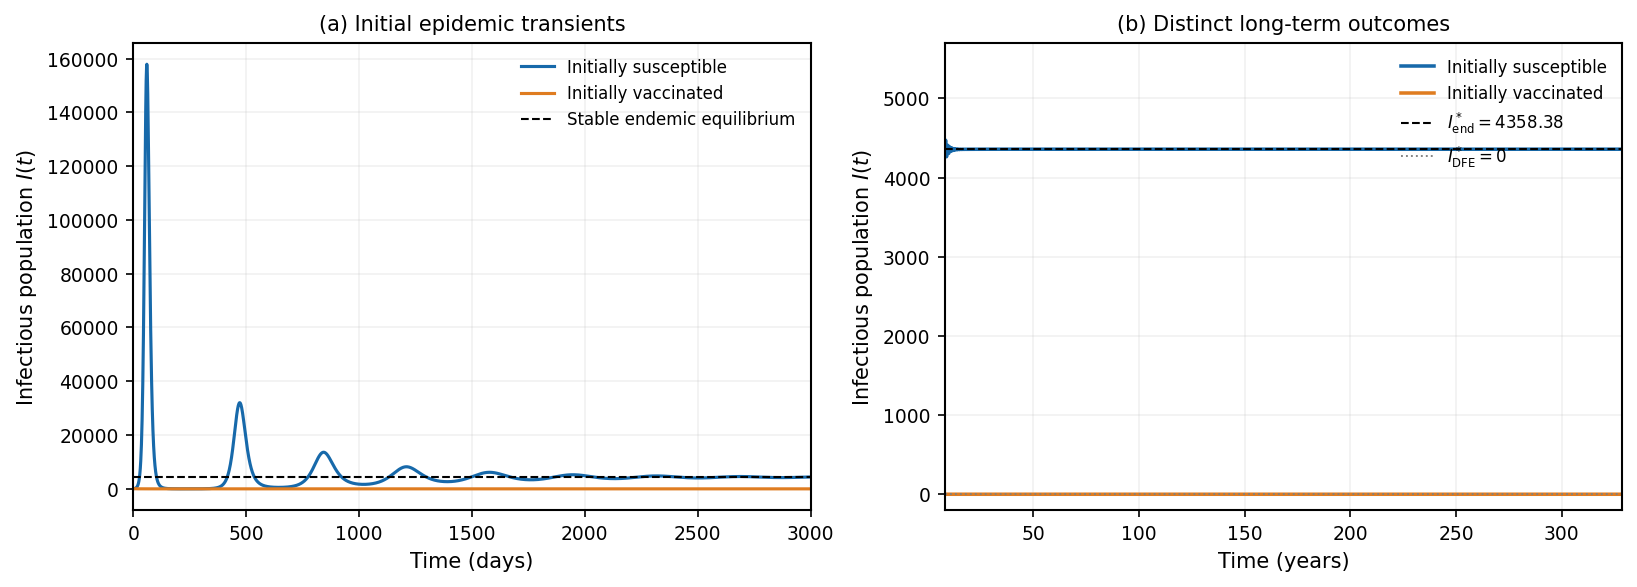


Figure files saved successfully.


In [26]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# 1. BASELINE MODEL PARAMETERS
# ============================================================

N = 1e6
beta = 0.6
eps = 0.8
phi = 0.005
sigma = 0.25
gamma = 0.2

wN = 1 / 730
wV = 1 / 365

lam = 0.5
mu = 0.05
k = 10
Tc = 0.5

# No direct vaccine waning: theta = 0


# ============================================================
# 2. ORIGINAL SEIR-VACCINATION-TRUST MODEL
# ============================================================

def rhs(t, y):
    S, V, E, I, RN, RV, T = y

    x = 1 / (1 + np.exp(-k * (T - Tc)))
    force = beta * I / N

    dS = (
        -force * S
        - phi * x * S
        + wN * RN
        + wV * RV
    )

    dV = (
        phi * x * S
        - (1 - eps) * force * V
    )

    dE = (
        force * (S + (1 - eps) * V)
        - sigma * E
    )

    dI = sigma * E - gamma * I

    dRN = (1 - x) * gamma * I - wN * RN
    dRV = x * gamma * I - wV * RV

    dT = lam * I / N - mu * T

    return np.array([dS, dV, dE, dI, dRN, dRV, dT])


# ============================================================
# 3. TWO DIFFERENT INITIAL CONDITIONS
# ============================================================

# Case A: Mostly susceptible population
y0_A = [
    999900,  # S
    0,       # V
    0,       # E
    100,     # I
    0,       # RN
    0,       # RV
    0.5      # T
]

# Case B: Mostly vaccinated population
y0_B = [
    0,       # S
    999900,  # V
    0,       # E
    100,     # I
    0,       # RN
    0,       # RV
    0.5      # T
]


# ============================================================
# 4. HIGH-ACCURACY NUMERICAL INTEGRATION
# ============================================================

def solve_model(y0):

    # Initial epidemic dynamics
    sol_short = solve_ivp(
        rhs,
        (0, 3000),
        y0,
        method="DOP853",
        rtol=2e-10,
        atol=1e-8,
        dense_output=True,
        max_step=3
    )

    if not sol_short.success:
        raise RuntimeError(sol_short.message)

    # Long-term dynamics
    sol_long = solve_ivp(
        rhs,
        (3000, 120000),
        sol_short.y[:, -1],
        method="DOP853",
        rtol=2e-10,
        atol=1e-8,
        dense_output=True,
        max_step=50
    )

    if not sol_long.success:
        raise RuntimeError(sol_long.message)

    return sol_short, sol_long


A_short, A_long = solve_model(y0_A)
B_short, B_long = solve_model(y0_B)


# ============================================================
# 5. PRINT NUMERICAL DIAGNOSTICS
# ============================================================

for label, short, long in [
    ("Initially susceptible", A_short, A_long),
    ("Initially vaccinated", B_short, B_long)
]:

    t_short = np.linspace(0, 3000, 3001)
    Y_short = short.sol(t_short)

    final_state = long.y[:, -1]
    residual = np.max(np.abs(rhs(120000, final_state)))

    print("\n" + "=" * 55)
    print(label)
    print("=" * 55)

    print(f"Peak infection: {np.max(Y_short[3]):.6f}")
    print(f"Final S: {final_state[0]:.6f}")
    print(f"Final V: {final_state[1]:.6f}")
    print(f"Final I: {final_state[3]:.9f}")
    print(f"Maximum RHS residual: {residual:.3e}")
    print(
        "Population conservation error:",
        abs(np.sum(final_state[:6]) - N)
    )


# ============================================================
# 6. PUBLICATION-QUALITY FIGURE
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 8,
    "pdf.fonttype": 42
})

fig, axs = plt.subplots(
    1, 2,
    figsize=(10.8, 3.8),
    constrained_layout=True
)

# Stable endemic equilibrium at lambda = 0.5
I_endemic = 4358.379856


# ------------------------------------------------------------
# PANEL (a): Initial epidemic transients
# ------------------------------------------------------------

t_short = np.linspace(0, 3000, 3001)

axs[0].plot(
    t_short,
    A_short.sol(t_short)[3],
    color="#1769aa",
    linewidth=1.5,
    label="Initially susceptible"
)

axs[0].plot(
    t_short,
    B_short.sol(t_short)[3],
    color="#df7c20",
    linewidth=1.5,
    label="Initially vaccinated"
)

axs[0].axhline(
    I_endemic,
    color="black",
    linewidth=1,
    linestyle="--",
    label="Stable endemic equilibrium"
)

axs[0].set(
    title="(a) Initial epidemic transients",
    xlabel="Time (days)",
    ylabel=r"Infectious population $I(t)$",
    xlim=(0, 3000)
)

axs[0].legend(
    loc="upper right",
    frameon=False
)


# ------------------------------------------------------------
# PANEL (b): Long-term outcomes
# ------------------------------------------------------------

t_long = np.linspace(3000, 120000, 1500)

axs[1].plot(
    t_long / 365,
    A_long.sol(t_long)[3],
    color="#1769aa",
    linewidth=1.7,
    label="Initially susceptible"
)

axs[1].plot(
    t_long / 365,
    B_long.sol(t_long)[3],
    color="#df7c20",
    linewidth=1.7,
    label="Initially vaccinated"
)

axs[1].axhline(
    I_endemic,
    color="black",
    linewidth=1,
    linestyle="--",
    label=r"$I^*_{\mathrm{end}}=4358.38$"
)

axs[1].axhline(
    0,
    color="gray",
    linewidth=0.9,
    linestyle=":",
    label=r"$I^*_{\mathrm{DFE}}=0$"
)

axs[1].set(
    title="(b) Distinct long-term outcomes",
    xlabel="Time (years)",
    ylabel=r"Infectious population $I(t)$",
    xlim=(3000 / 365, 120000 / 365),
    ylim=(-200, 5700)
)

axs[1].legend(
    loc="upper right",
    frameon=False
)

# Grid formatting
for ax in axs:
    ax.grid(alpha=0.17)


# ============================================================
# 7. SAVE FIGURE
# ============================================================

fig.savefig(
    "bistability_trajectories.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "bistability_trajectories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure files saved successfully.")


In [27]:

# Numerical verification of the saddle-node fold
# Trust-mediated vaccination epidemic model

import mpmath as mp

# Set numerical precision to 70 decimal digits
mp.mp.dps = 70

# --------------------------------------------------
# 1. Baseline model parameters
# --------------------------------------------------

N = mp.mpf("1000000")
beta = mp.mpf("0.6")
phi = mp.mpf("0.005")
epsilon = mp.mpf("0.8")
sigma = mp.mpf("0.25")
gamma = mp.mpf("0.2")

omega_N = 1 / mp.mpf("730")
omega_V = 1 / mp.mpf("365")

mu = mp.mpf("0.05")
k = mp.mpf("10")
T_c = mp.mpf("0.5")

# --------------------------------------------------
# 2. Define the equilibrium residual F(I, lambda)
# --------------------------------------------------

def F(I, lam):

    i = I / N

    # Equilibrium trust and vaccination preference
    T = lam * i / mu
    x = 1 / (1 + mp.exp(-k * (T - T_c)))

    # Equilibrium compartments
    S = N * gamma * i / (beta * i + phi * x)

    V = (
        N * phi * x * gamma
        / ((1 - epsilon) * beta * (beta * i + phi * x))
    )

    E = N * gamma * i / sigma

    R_N = N * (1 - x) * gamma * i / omega_N
    R_V = N * x * gamma * i / omega_V

    # Population conservation residual
    return S + V + E + I + R_N + R_V - N


# --------------------------------------------------
# 3. Evaluate at the manuscript's rounded coordinates
# --------------------------------------------------

I_reported = mp.mpf("152.550043043719")
lambda_reported = mp.mpf("31.125727294988")

F_reported = F(I_reported, lambda_reported)

FI_reported = mp.diff(
    lambda I: F(I, lambda_reported),
    I_reported
)

print("=" * 65)
print("RESIDUALS AT REPORTED ROUNDED COORDINATES")
print("=" * 65)

print("|F|   =", mp.nstr(abs(F_reported), 20))
print("|F_I| =", mp.nstr(abs(FI_reported), 20))


# --------------------------------------------------
# 4. Refine the saddle-node coordinates
#    Solve F = 0 and F_I = 0 simultaneously
# --------------------------------------------------

def F_I(I, lam):
    return mp.diff(lambda z: F(z, lam), I)

I_SN, lambda_SN = mp.findroot(
    (F, F_I),
    (I_reported, lambda_reported),
    tol=mp.mpf("1e-60")
)

# --------------------------------------------------
# 5. Compute residuals and nondegeneracy derivatives
# --------------------------------------------------

residual_F = abs(F(I_SN, lambda_SN))
residual_FI = abs(F_I(I_SN, lambda_SN))

F_II = mp.diff(
    lambda z: F(z, lambda_SN),
    I_SN,
    2
)

F_lambda = mp.diff(
    lambda z: F(I_SN, z),
    lambda_SN
)

print("\n" + "=" * 65)
print("REFINED SADDLE-NODE COORDINATES")
print("=" * 65)

print("I_SN      =", mp.nstr(I_SN, 35))
print("lambda_SN =", mp.nstr(lambda_SN, 35))

print("\n" + "=" * 65)
print("HIGH-PRECISION FOLD RESIDUALS")
print("=" * 65)

print("|F|   =", mp.nstr(residual_F, 20))
print("|F_I| =", mp.nstr(residual_FI, 20))

print("\n" + "=" * 65)
print("NONDEGENERACY CONDITIONS")
print("=" * 65)

print("F_II     =", mp.nstr(F_II, 20))
print("F_lambda =", mp.nstr(F_lambda, 20))

if abs(F_II) > mp.mpf("1e-10") and \
   abs(F_lambda) > mp.mpf("1e-10"):
    print("\nNondegeneracy conditions satisfied.")
else:
    print("\nNondegeneracy conditions need further examination.")


RESIDUALS AT REPORTED ROUNDED COORDINATES
|F|   = 2.4178482611172477487e-9
|F_I| = 1.661345518936314141e-11

REFINED SADDLE-NODE COORDINATES
I_SN      = 152.55004304371907636971143422324986
lambda_SN = 31.125727294988242294749025352720555

HIGH-PRECISION FOLD RESIDUALS
|F|   = 0.0
|F_I| = 1.3265154900625066945e-74

NONDEGENERACY CONDITIONS
F_II     = 14.070286476166072385
F_lambda = 9978.95443810982247

Nondegeneracy conditions satisfied.


In [28]:
!pip install numpy scipy sympy mpmath
!python validate_recovery_allocation.py


python3: can't open file '/content/validate_recovery_allocation.py': [Errno 2] No such file or directory
